# 03 — Option Surface Distributions

**Purpose:** characterize the 0DTE option-surface features before any of them enter the regime feature contract, and test the three surface questions raised by the project audit:

| Audit item | Question tested here |
|---|---|
| **A2** | Does the fixed log-moneyness grid ($k = \pm2.5\%, \pm5\%$) mean the same thing at different times to expiry and across assets? Would a standardized-moneyness grid $z = k / (\sigma_{ATM}\sqrt{\tau})$ be more stationary? |
| **B2** | How much of the "preferred" surface is Deribit's mark model rather than market quotes, and do switches between the two sources create artificial jumps in surface changes? |
| **B1** | How many valid option snapshots are lost because surface eligibility requires the futures stream? |
| **B4** | Do features behave differently inside the 07:30–08:00 UTC settlement window? |

This notebook:

- opens `research.duckdb` **read-only**, in a **UTC** session;
- uses `time_series_feature_state` for the model-facing features and the long-form option views (`normalized_option_chain`, `smile_node_state`) for diagnostics the feature table cannot answer;
- builds a **standardized-moneyness prototype in memory only**. Nothing is written to the database.

It does **not**:

- impute, winsorize, or standardize anything;
- fit an SSVI or any arbitrage-free surface;
- change the production surface (if the evidence favours $z$-space, the change goes into `src/data_engineering/surfaces/` as a separate, reviewed step);
- define final time-to-expiry bins. The buckets below are exploratory.

> Time to expiry and time of day are the same clock for a daily 0DTE (expiry 08:00 UTC). Every "TTE effect" in this notebook is also an intraday-seasonality effect.

## 1. Environment and read-only connection

In [1]:
from pathlib import Path
import os
import math
import time
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"
if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

print(f"Research DB:        {DB_PATH}")
print("Connection mode:    read-only")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])


def q(sql, label):
    """Run a read-only query and report its size and runtime."""
    started = time.perf_counter()
    df = con.execute(sql).df()
    print(f"[{label}] {len(df):,} rows in {time.perf_counter() - started:,.1f}s")
    return df


def relation_columns(name):
    return set(con.execute(f"DESCRIBE SELECT * FROM {name}").df()["column_name"])

Research DB:        D:\MarketData\Deribit\database\research.duckdb
Connection mode:    read-only
Session time zone: UTC


## 2. Load the model-facing option features

Feature families:

- **Fixed-$k$ levels:** ATM IV, symmetric IV differences ("skew") and curvature at $k=\pm2.5\%$ and $\pm5\%$, local skew slopes.
- **Delta levels:** 25Δ/10Δ put and call IV, risk reversals (RR) and butterflies (BF).
- **Dynamics:** 5m / 15m / 1h changes, blocked across the 08:00 session boundary by the pipeline.
- **Quality metadata:** quality tier, usability flags, interpolation spans, eligible rows and option spreads.

IV units are detected from the data and printed; the standardized-moneyness calculation converts to decimals.

In [2]:
features = con.execute(
    "SELECT * FROM time_series_feature_state ORDER BY state_time, underlying"
).df()
features["state_time"] = pd.to_datetime(features["state_time"], utc=True)

OPTION_LEVEL = [
    "option_iv_atm_forward",
    "option_skew_025", "option_skew_050",
    "option_curvature_025", "option_curvature_050",
    "option_local_skew_slope_025", "option_local_skew_slope_050",
    "iv_put_25d", "iv_call_25d", "rr_25d", "bf_25d",
    "iv_put_10d", "iv_call_10d", "rr_10d", "bf_10d",
]
OPTION_DYNAMIC = [
    "atm_iv_change_5m", "atm_iv_change_15m", "atm_iv_change_1h",
    "skew_025_change_5m", "skew_025_change_15m", "skew_025_change_1h",
    "curvature_025_change_5m", "curvature_025_change_15m", "curvature_025_change_1h",
    "skew_050_change_5m", "rr_25d_change_5m", "bf_25d_change_5m",
]
OPTION_QUALITY = [
    "core_smile_quality_tier", "core_smile_tight", "core_smile_usable",
    "wing_050_usable", "full_grid_usable",
    "core_max_interpolation_span", "wing_050_max_interpolation_span",
    "full_grid_max_interpolation_span",
    "delta_25d_smile_available", "full_delta_smile_available",
    "max_delta_interpolation_span", "median_delta_interpolation_span",
    "option_base_eligible_rows", "option_two_sided_eligible_rows",
    "option_median_two_sided_spread_bps", "option_p90_two_sided_spread_bps",
]

for name, cols in [("level", OPTION_LEVEL), ("dynamic", OPTION_DYNAMIC), ("quality", OPTION_QUALITY)]:
    missing = [c for c in cols if c not in features.columns]
    print(f"{name:<8} {len(cols) - len(missing):>2} / {len(cols)} available" + (f" | missing: {missing}" if missing else ""))

OPTION_LEVEL = [c for c in OPTION_LEVEL if c in features.columns]
OPTION_DYNAMIC = [c for c in OPTION_DYNAMIC if c in features.columns]

# IV units: Deribit publishes IV in percent. Detect rather than assume.
atm_median = pd.to_numeric(features["option_iv_atm_forward"], errors="coerce").median()
IV_TO_DECIMAL = 0.01 if atm_median > 3 else 1.0
print(f"\nMedian ATM IV: {atm_median:.4g} -> IV unit = {'percent' if IV_TO_DECIMAL == 0.01 else 'decimal'}")

MINUTES_PER_YEAR = 365.0 * 24.0 * 60.0
features["tte_years"] = features["minutes_to_expiry"] / MINUTES_PER_YEAR
features["atm_sigma_sqrt_t"] = (
    pd.to_numeric(features["option_iv_atm_forward"], errors="coerce") * IV_TO_DECIMAL
    * np.sqrt(features["tte_years"])
)

# Exploratory buckets only; they are not model boundaries.
TTE_EDGES = [0, 30, 60, 180, 360, 720, 1080, 1440]
TTE_LABELS = ["≤30m (settle)", "30m–1h", "1–3h", "3–6h", "6–12h", "12–18h", "18–24h"]
features["tte_bucket"] = pd.cut(features["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)
features["in_settlement_window"] = features["minutes_to_expiry"] <= 30

ASSETS = sorted(features["underlying"].dropna().unique())
print(f"Rows: {len(features):,} | assets: {ASSETS}")
print(f"States: {features['state_time'].min()} → {features['state_time'].max()}")

level    15 / 15 available
dynamic  12 / 12 available
quality  16 / 16 available

Median ATM IV: 44.52 -> IV unit = percent
Rows: 32,256 | assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
States: 2026-09-19 08:00:00+00:00 → 2026-10-05 07:55:00+00:00


In [3]:
CENTRAL_LOWER_Q, CENTRAL_UPPER_Q = 0.005, 0.995
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]


def clean_numeric(df, column):
    return pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()


def feature_summary(df, columns, group_col=None):
    rows = []
    iterator = [("ALL", df)] if group_col is None else df.groupby(group_col, dropna=False, observed=True)
    for group_name, group in iterator:
        for col in columns:
            if col not in group.columns:
                continue
            s = clean_numeric(group, col)
            if s.empty:
                continue
            qv = s.quantile(TAIL_QS)
            rows.append({
                "group": group_name, "feature": col, "n": len(s),
                "missing_pct": 100.0 * (len(group) - len(s)) / max(len(group), 1),
                "mean": s.mean(), "std": s.std(), "skew": s.skew(), "excess_kurtosis": s.kurt(),
                "min": s.min(), "q001": qv.loc[0.001], "q01": qv.loc[0.01], "q05": qv.loc[0.05],
                "median": qv.loc[0.50], "q95": qv.loc[0.95], "q99": qv.loc[0.99], "q999": qv.loc[0.999],
                "max": s.max(),
            })
    return pd.DataFrame(rows)


def plot_asset_histograms(df, column, bins=60):
    ncols = 2
    nrows = math.ceil(len(ASSETS) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, asset in zip(axes, ASSETS):
        s = clean_numeric(df[df["underlying"] == asset], column)
        if s.empty:
            ax.text(0.5, 0.5, "No observations", ha="center", va="center")
        else:
            lo, hi = s.quantile(CENTRAL_LOWER_Q), s.quantile(CENTRAL_UPPER_Q)
            ax.hist(s[(s >= lo) & (s <= hi)], bins=bins)
        ax.set_title(str(asset))
    for ax in axes[len(ASSETS):]:
        ax.axis("off")
    fig.suptitle(f"{column} — per-asset central 99%", y=1.01)
    plt.tight_layout()
    plt.show()


def as_bool(s):
    """Nullable/boolean-like column -> plain bool (missing = False)."""
    if s.dtype == bool:
        return s
    mapped = s.map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))
    return mapped.astype(bool)


def median_by_tte(df, column, assets=None):
    """Median of a feature at each minutes_to_expiry, per asset."""
    assets = assets or ASSETS
    out = (
        df[df["underlying"].isin(assets)]
        .assign(_v=lambda d: pd.to_numeric(d[column], errors="coerce"))
        .groupby(["underlying", "minutes_to_expiry"])["_v"]
        .median()
        .unstack("underlying")
        .sort_index(ascending=False)
    )
    return out


def plot_median_by_tte(df, columns, title, logy=False):
    fig, axes = plt.subplots(1, len(columns), figsize=(6.5 * len(columns), 4.6), squeeze=False)
    for ax, col in zip(axes[0], columns):
        m = median_by_tte(df, col)
        for asset in m.columns:
            ax.plot(m.index / 60.0, m[asset], linewidth=1.2, label=str(asset))
        ax.invert_xaxis()
        ax.set_xlabel("hours to expiry")
        ax.set_title(col)
        if logy:
            ax.set_yscale("log")
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def eta_squared(df, column, group_col="tte_bucket"):
    """Share of a feature's variance explained by bucket medians (within one asset).

    0 means the clock explains nothing; 1 means the feature is a deterministic
    function of the clock bucket.
    """
    d = df[[column, group_col]].copy()
    d[column] = pd.to_numeric(d[column], errors="coerce")
    d = d.dropna()
    if len(d) < 50 or d[column].var() == 0:
        return np.nan
    group_mean = d.groupby(group_col, observed=True)[column].transform("mean")
    return float(((group_mean - d[column].mean()) ** 2).sum() / ((d[column] - d[column].mean()) ** 2).sum())


def within_session_acf(df, column, max_lag=24):
    """ACF on the exact 5-minute grid, never crossing a session boundary."""
    rows = []
    for asset, g in df.groupby("underlying"):
        g = g.sort_values("state_time")
        x = pd.to_numeric(g[column], errors="coerce")
        for lag in range(1, max_lag + 1):
            lx = x.shift(lag)
            ok = (
                x.notna() & lx.notna()
                & ((g["state_time"] - g["state_time"].shift(lag)) == pd.Timedelta(minutes=5 * lag))
                & (g["session_id"] == g["session_id"].shift(lag))
            )
            rows.append({
                "underlying": asset, "feature": column, "lag_minutes": 5 * lag,
                "n_pairs": int(ok.sum()),
                "acf": x[ok].corr(lx[ok]) if ok.sum() >= 20 else np.nan,
            })
    return pd.DataFrame(rows)

# Part A — Coverage

## 3. Option snapshots lost to the futures gate (audit B1)

Surface eligibility in `option_normalization.py` requires `state_research_ready`, which requires a complete **futures** stream. The option forward is built from the option chain itself, so the surface does not need the futures.

`lost_to_futures_gate` counts states with a valid option snapshot (`option_snapshot_ready`) but no surface because the futures side was not ready. These states include every session before the futures collector started and every futures reconnect.

In [4]:
cms_cols = relation_columns("canonical_market_state")
needed = {"option_snapshot_ready", "state_research_ready", "price_features_ready"}
if needed.issubset(cms_cols):
    gate = q(
        """
        SELECT
            underlying,
            expiry_date,
            COUNT(*) AS states,
            SUM(CASE WHEN option_snapshot_ready THEN 1 ELSE 0 END) AS option_ready,
            SUM(CASE WHEN state_research_ready THEN 1 ELSE 0 END) AS research_ready,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(state_research_ready, FALSE)
                     THEN 1 ELSE 0 END) AS lost_to_futures_gate,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(price_features_ready, FALSE)
                     THEN 1 ELSE 0 END) AS option_ok_futures_not_ready
        FROM canonical_market_state
        GROUP BY 1, 2
        ORDER BY 2, 1
        """,
        "futures-gate loss",
    )
    by_asset = gate.groupby("underlying")[["states", "option_ready", "research_ready", "lost_to_futures_gate"]].sum()
    by_asset["lost_pct_of_option_ready"] = 100 * by_asset["lost_to_futures_gate"] / by_asset["option_ready"]
    display(by_asset.round(2))
    display(
        gate.pivot_table(index="expiry_date", columns="underlying", values="lost_to_futures_gate", aggfunc="sum")
    )
else:
    print(f"canonical_market_state lacks {needed - cms_cols}; section skipped.")
    gate = pd.DataFrame()

[futures-gate loss] 112 rows in 0.4s


,states,option_ready,research_ready,lost_to_futures_gate,lost_pct_of_option_ready
underlying,,,,,
AVAX,4608,4239.0,3934.0,305.0,7.2
BTC,4608,4239.0,3934.0,305.0,7.2
ETH,4608,4239.0,3934.0,305.0,7.2
HYPE,4608,4239.0,3934.0,305.0,7.2
SOL,4608,4239.0,3934.0,305.0,7.2
TRX,4608,4239.0,3934.0,305.0,7.2
XRP,4608,4239.0,3934.0,305.0,7.2


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
expiry_date,,,,,,,
2026-09-20,15.0,15.0,15.0,15.0,15.0,15.0,15.0
2026-09-21,204.0,204.0,204.0,204.0,204.0,204.0,204.0
2026-09-22,33.0,33.0,33.0,33.0,33.0,33.0,33.0
2026-09-23,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-24,3.0,3.0,3.0,3.0,3.0,3.0,3.0
2026-09-25,5.0,5.0,5.0,5.0,5.0,5.0,5.0
2026-09-26,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Surface availability through the session

Which surface representations exist at each time to expiry? The fixed-$k$ core needs strikes bracketing $k=0, \pm2.5\%$; the delta smile needs options with $|\Delta|$ around 0.25 and 0.10, which disappear near expiry as deltas collapse to 0 or 1.

Share of states with a primary option family where each representation is available (%):


core_smile_usable  core_smile_tight  wing_050_usable  full_grid_usable  delta_25d_smile_available  full_delta_smile_available
underlying tte_bucket                                                                                                                                  
AVAX       ≤30m (settle)               93.3              93.3             93.3              93.3                        1.1                         1.1
           30m–1h                      92.2              92.2             92.2              92.2                       10.0                        10.0
           1–3h                        92.2              92.2             92.2              92.2                       46.8                        46.8
           3–6h                        93.0              93.0             93.0              91.7                       84.1                        84.1
           6–12h                       92.1              92.1             92.1              91.2                       89.2                        89.2
           12–18h                      91.8              91.8             91.8              89.2                       91.8                        91.8
           18–24h                      93.8              93.8             93.8              92.4                       93.8                        93.8
BTC        ≤30m (settle)               93.3              93.3             93.3              78.9                        0.0                         0.0
           30m–1h                      92.2              92.2             92.2              75.6                        0.0                         0.0
           1–3h                        92.2              92.2             92.2              72.7                        6.1                         6.1
           3–6h                        93.0              93.0             90.9              75.4                       24.1                        24.1
           6–12h                       92.1              92.1             85.6              75.2                       55.7                        55.7
           12–18h                      91.8              91.8             85.6              69.3                       77.5                        77.5
           18–24h                      93.8              93.8             93.8              74.9                       85.5                        85.5
ETH        ≤30m (settle)               93.3              93.3             93.3              80.0                        0.0                         0.0
           30m–1h                      92.2              92.2             92.2              80.0                        2.2                         2.2
           1–3h                        92.2              92.2             92.2              78.8                        9.7                         9.7
           3–6h                        93.0              93.0             93.0              79.6                       30.7                        30.7
           6–12h                       92.1              92.1             92.1              79.0                       62.3                        62.3
           12–18h                      91.8              91.8             91.8              78.6                       81.2                        81.2
           18–24h                      93.8              93.8             93.8              83.2                       86.8                        86.8
HYPE       ≤30m (settle)               93.3              93.3             93.3              90.0                        0.0                         0.0
           30m–1h                      92.2              92.2             92.2              92.2                        1.1                         1.1
           1–3h                        92.2              92.2             92.2              92.2                       13.4                        13.4
           3–6h                        93.0              93.0             

core_smile_quality_tier,A,D
underlying,,
AVAX,92.6,7.4
BTC,92.6,7.4
ETH,92.6,7.4
HYPE,92.6,7.4
SOL,92.6,7.4
TRX,92.6,7.4
XRP,89.8,10.2


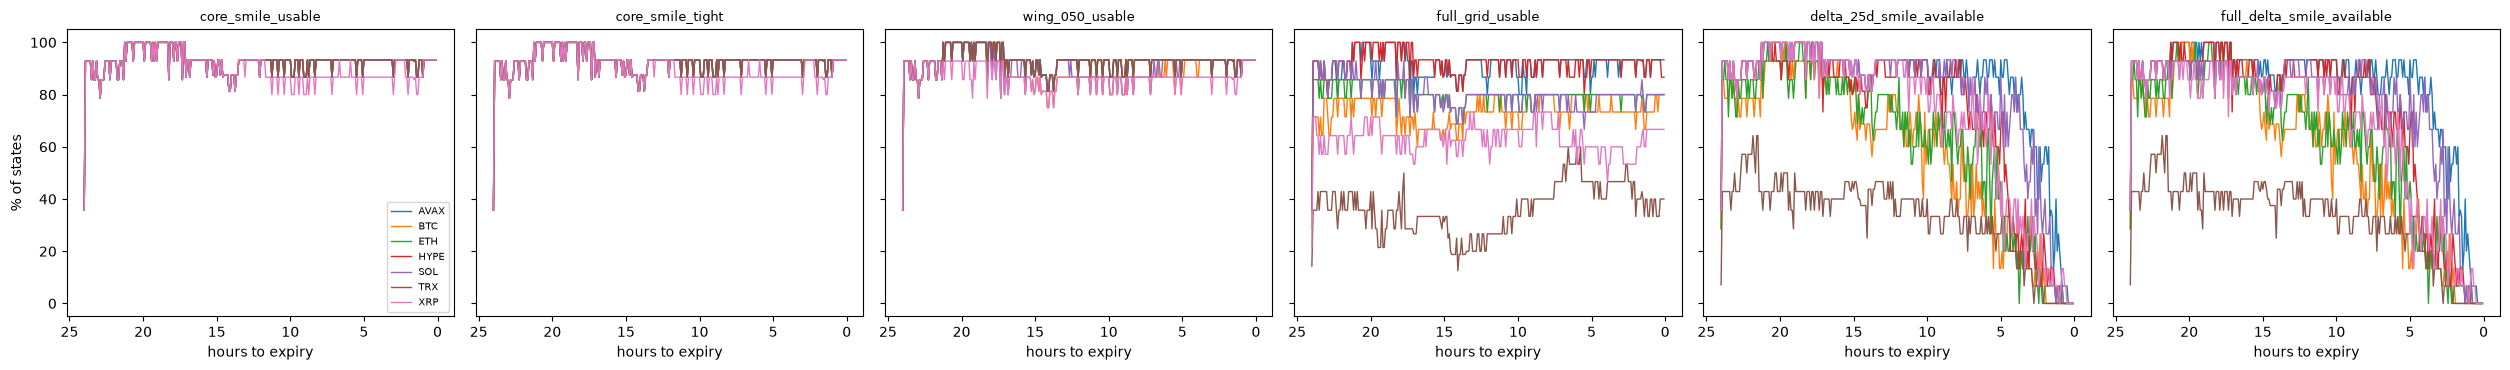

In [5]:
avail_cols = [c for c in [
    "core_smile_usable", "core_smile_tight", "wing_050_usable", "full_grid_usable",
    "delta_25d_smile_available", "full_delta_smile_available",
] if c in features.columns]

opt_rows = features[features["primary_option_family_id"].notna()] if "primary_option_family_id" in features.columns else features
availability = (
    opt_rows.assign(**{c: as_bool(opt_rows[c]) for c in avail_cols})
    .groupby(["underlying", "tte_bucket"], observed=True)[avail_cols]
    .mean()
    .mul(100)
    .round(1)
)
print("Share of states with a primary option family where each representation is available (%):")
display(availability)

if "core_smile_quality_tier" in features.columns:
    tiers = (
        opt_rows.groupby(["underlying", "core_smile_quality_tier"]).size()
        .unstack(fill_value=0)
    )
    display(tiers.div(tiers.sum(axis=1), axis=0).mul(100).round(1))

fig, axes = plt.subplots(1, len(avail_cols), figsize=(4.2 * len(avail_cols), 3.8), sharey=True)
for ax, col in zip(np.atleast_1d(axes), avail_cols):
    m = (
        opt_rows.assign(_v=as_bool(opt_rows[col]).astype(float))
        .groupby(["minutes_to_expiry", "underlying"])["_v"].mean().unstack()
        .sort_index(ascending=False)
    )
    for asset in m.columns:
        ax.plot(m.index / 60, 100 * m[asset], linewidth=1, label=asset)
    ax.invert_xaxis()
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("hours to expiry")
np.atleast_1d(axes)[0].set_ylabel("% of states")
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part B — Level Distributions

## 5. Pooled and per-asset distributions

ATM IV levels differ several-fold across assets, so pooled quantiles mainly describe the asset mix. The per-asset table is the relevant one.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,option_iv_atm_forward,27523,14.673239,47.777620,23.346489,0.743197,4.124258,8.654510,10.756624,13.135651,17.748469,44.524728,88.710157,102.791686,123.146203,457.556512
1,ALL,option_skew_025,27419,14.995660,3.053471,9.419462,8.490785,260.875480,-56.083210,-48.434144,-16.870000,-8.649549,2.867418,15.221104,24.694249,66.479585,379.486618
2,ALL,option_skew_050,27051,16.136533,4.239660,12.319244,1.057867,12.979760,-76.863050,-54.120622,-28.741583,-13.431305,3.896498,22.597386,37.504606,90.823909,140.380268
3,ALL,option_curvature_025,27419,14.995660,9.042142,8.173885,-3.646321,340.161598,-416.786227,-14.181589,-1.406244,0.903798,7.701573,21.784507,32.260661,53.312580,198.451851
4,ALL,option_curvature_050,27051,16.136533,20.238294,10.411950,-2.865025,142.870760,-405.665181,-4.243939,2.664144,6.808865,19.196833,36.853600,50.613049,70.280790,90.968362
5,ALL,option_local_skew_slope_025,27419,14.995660,61.069423,188.389247,8.490785,260.875480,-1121.664206,-968.682877,-337.400000,-172.990980,57.348362,304.422077,493.884990,1329.591705,7589.732356
6,ALL,option_local_skew_slope_050,27051,16.136533,42.396603,123.192441,1.057867,12.979760,-768.630504,-541.206220,-287.415827,-134.313052,38.964976,225.973860,375.046057,908.239091,1403.802684
7,ALL,iv_put_25d,22520,30.183532,51.064404,22.910891,0.718826,6.669723,10.949474,11.786667,13.717384,19.782840,50.078722,90.706503,103.464193,126.154908,512.549982
8,ALL,iv_call_25d,22948,28.856647,53.847217,24.532155,0.412755,-0.403811,12.329855,13.060054,15.348928,20.460170,53.479926,97.135740,112.739527,131.405577,244.626770
9,ALL,rr_25d,19537,39.431424,3.392269,6.187968,-21.664632,1870.223793,-474.442084,-14.759743,-7.152818,-3.688114,2.908452,12.280505,17.040417,26.068361,198.183963


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,option_iv_atm_forward,3934,14.626736,75.980286,17.861815,-0.120324,-0.594410,37.049039,37.990789,38.926806,42.897888,77.675330,101.670014,117.817717,122.707256,134.990000
1,AVAX,option_skew_025,3934,14.626736,4.539421,7.577589,1.190370,15.537094,-44.400912,-36.590850,-19.536850,-4.669493,4.285080,15.009028,30.137712,64.046856,66.479585
2,AVAX,option_skew_050,3934,14.626736,8.280495,16.863613,2.137570,20.341173,-76.863050,-70.941946,-40.527199,-10.947632,7.019418,26.910624,61.966108,139.620000,140.380268
3,AVAX,option_curvature_025,3934,14.626736,5.316983,5.761353,3.086772,15.293295,-25.251217,-7.919429,-0.456434,0.817242,3.752370,15.951803,29.000228,49.443847,52.235120
4,AVAX,option_curvature_050,3934,14.626736,16.080352,10.642127,2.591048,10.373518,-18.175527,-2.372570,2.586213,5.341198,14.198118,34.185657,60.610672,90.074060,90.968362
5,AVAX,option_local_skew_slope_025,3934,14.626736,90.788414,151.551790,1.190370,15.537094,-888.018232,-731.817003,-390.737001,-93.389867,85.701603,300.180570,602.754239,1280.937110,1329.591705
6,AVAX,option_local_skew_slope_050,3934,14.626736,82.804950,168.636126,2.137570,20.341173,-768.630504,-709.419462,-405.271986,-109.476317,70.194178,269.106237,619.661075,1396.200000,1403.802684
7,AVAX,iv_put_25d,3671,20.334201,76.606845,18.135823,-0.155691,-0.687761,37.265044,37.461717,38.866567,42.798424,78.388665,102.520101,117.677900,121.691358,122.963310
8,AVAX,iv_call_25d,3720,19.270833,81.007775,19.049947,-0.072812,-0.508427,38.205691,39.178133,41.322190,46.063184,83.322304,108.736214,126.331627,132.173269,134.836548
9,AVAX,rr_25d,3534,23.307292,4.648685,3.719420,0.195922,5.637723,-19.501503,-15.142700,-4.376956,-0.879173,4.415154,10.823268,13.904425,27.808159,31.173967


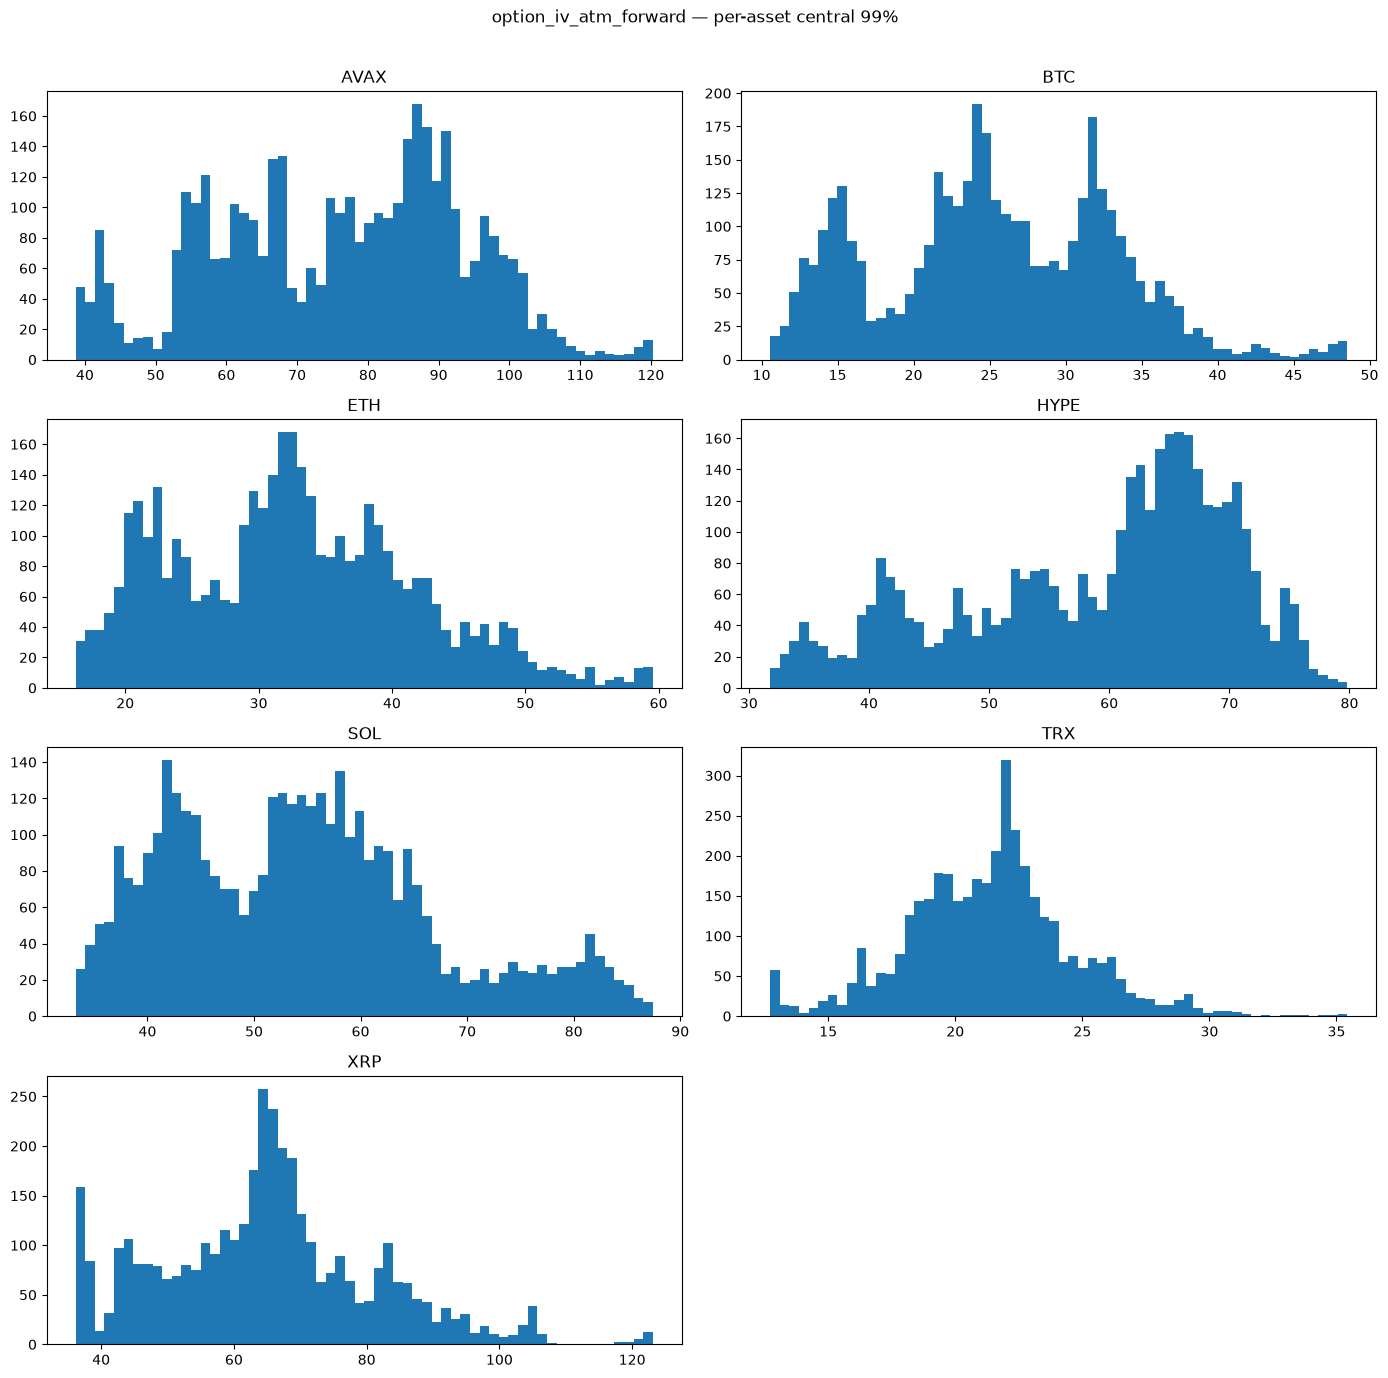

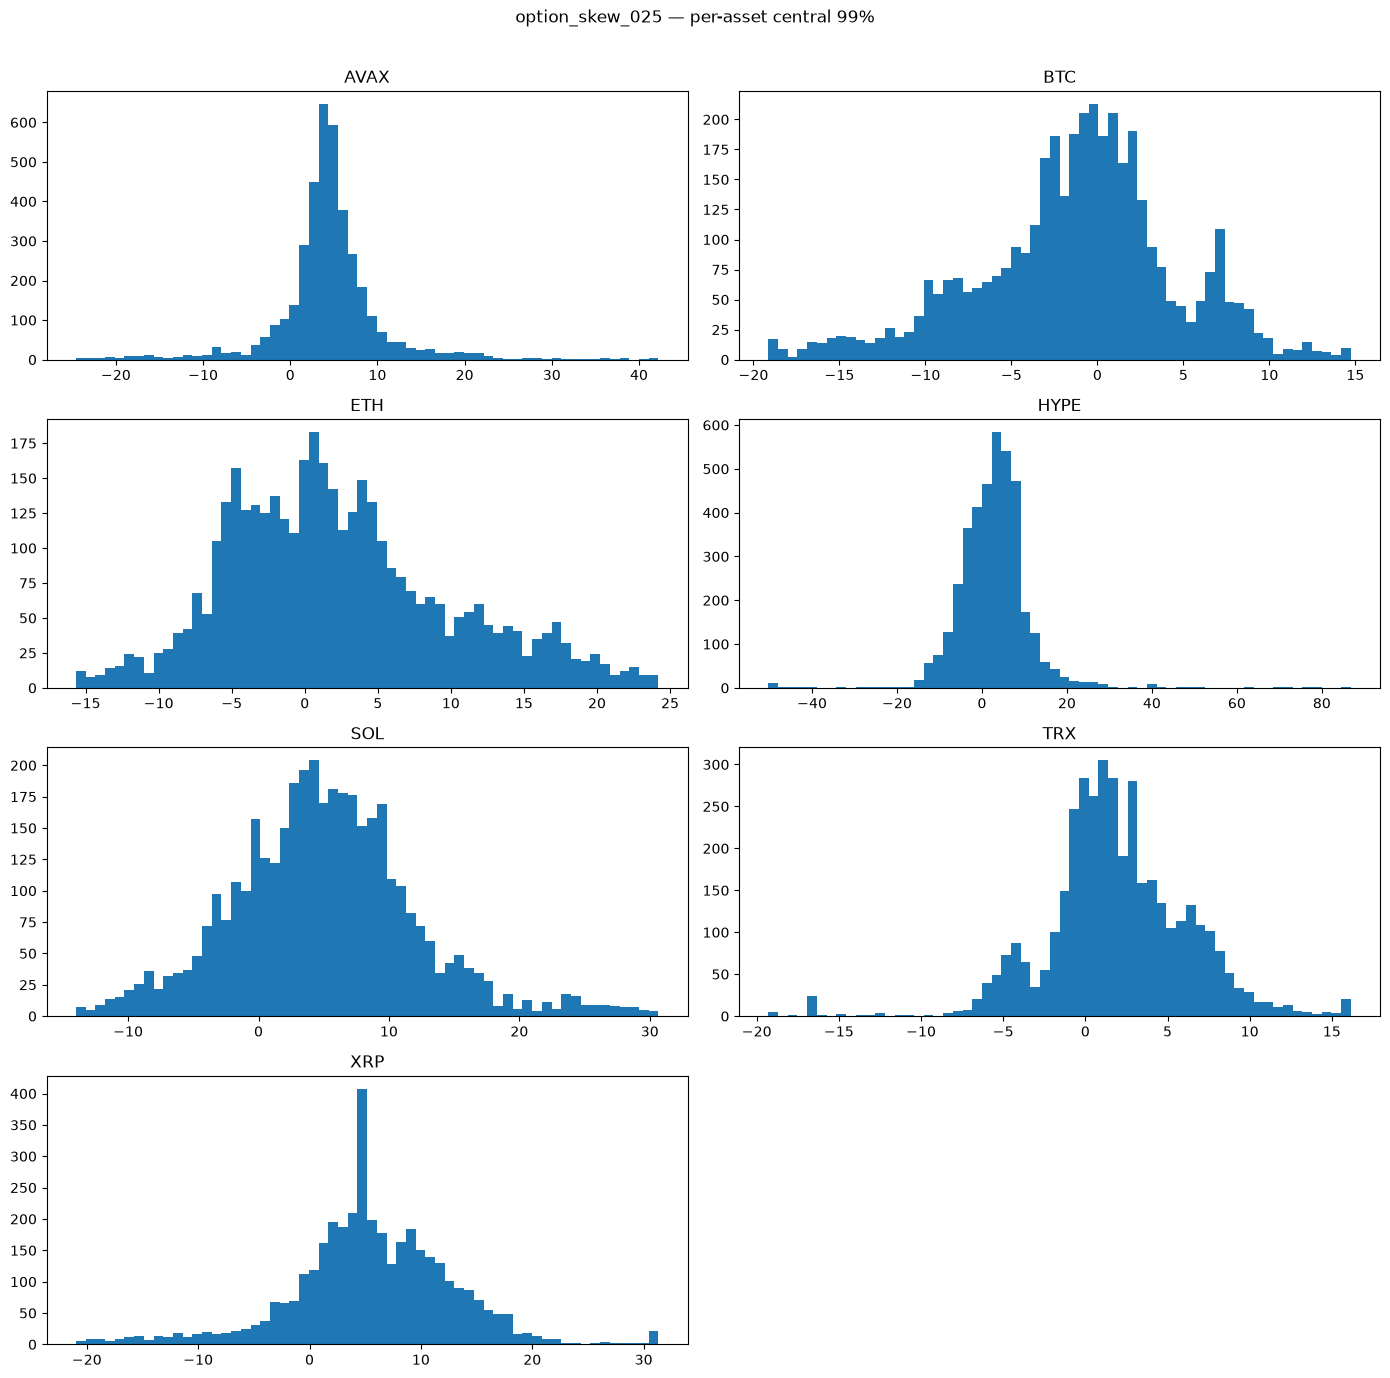

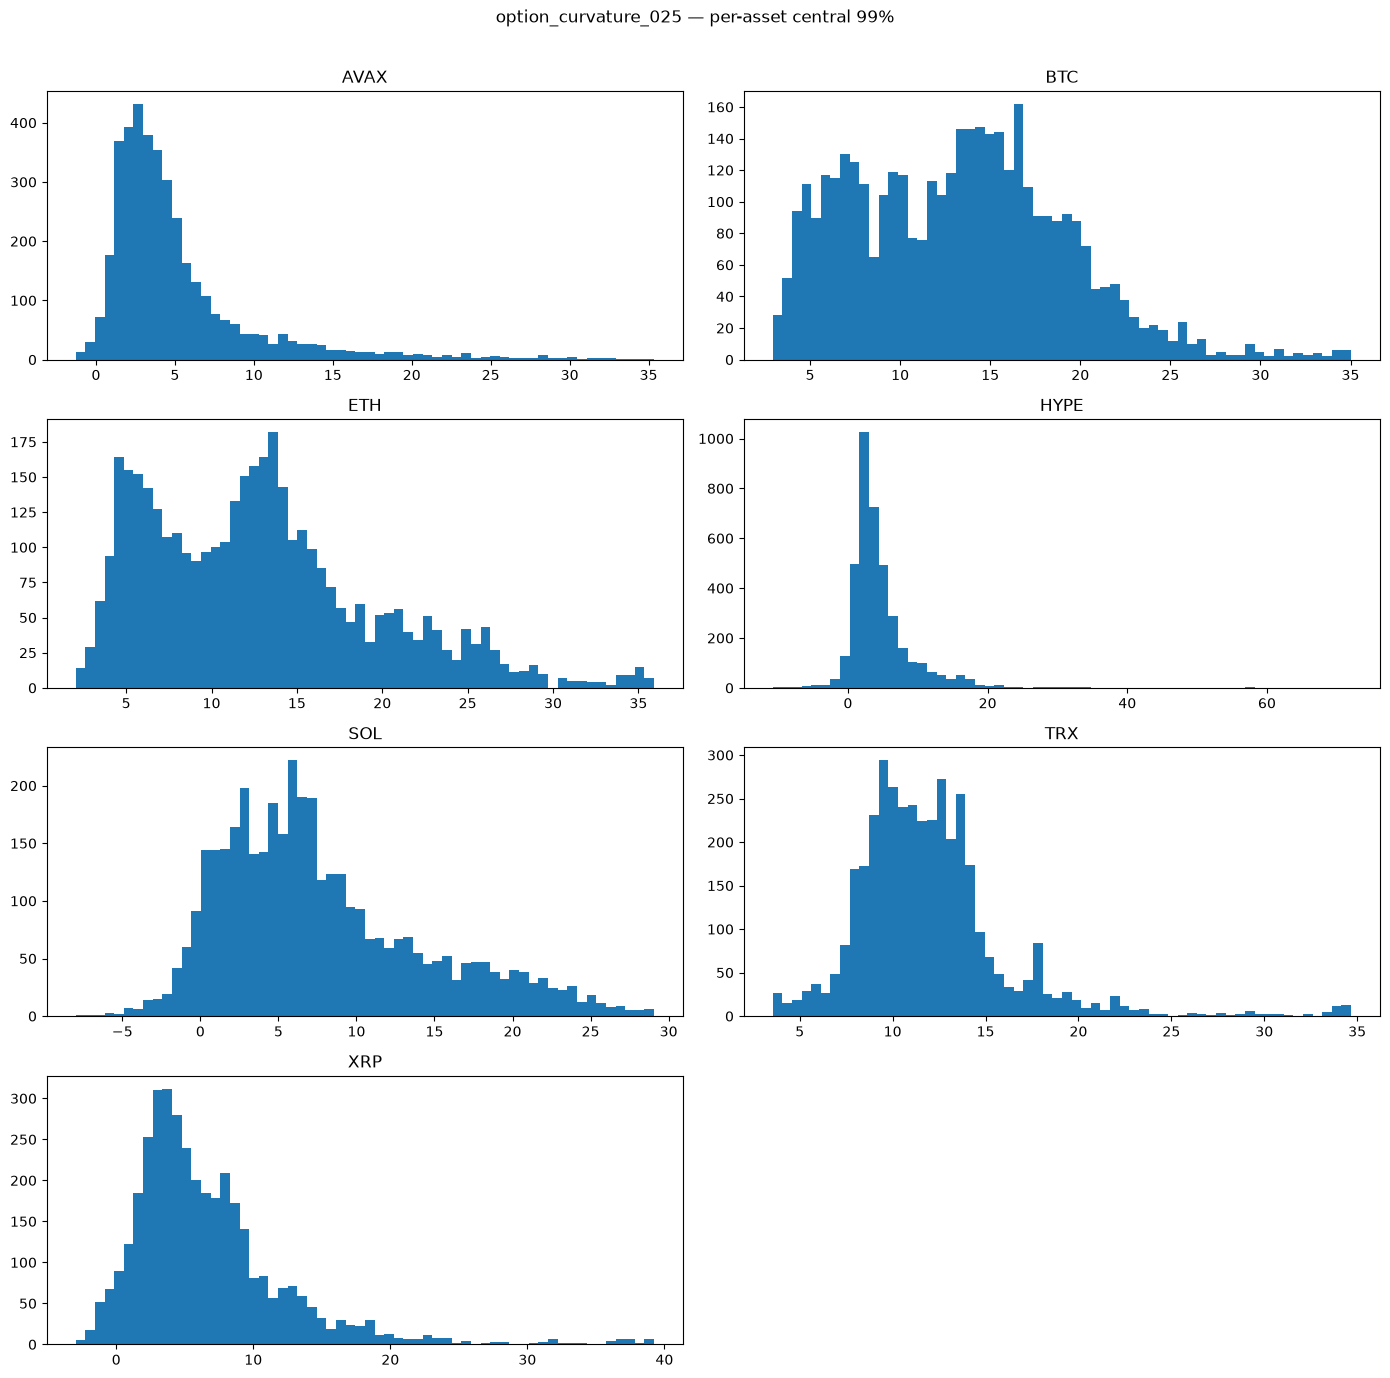

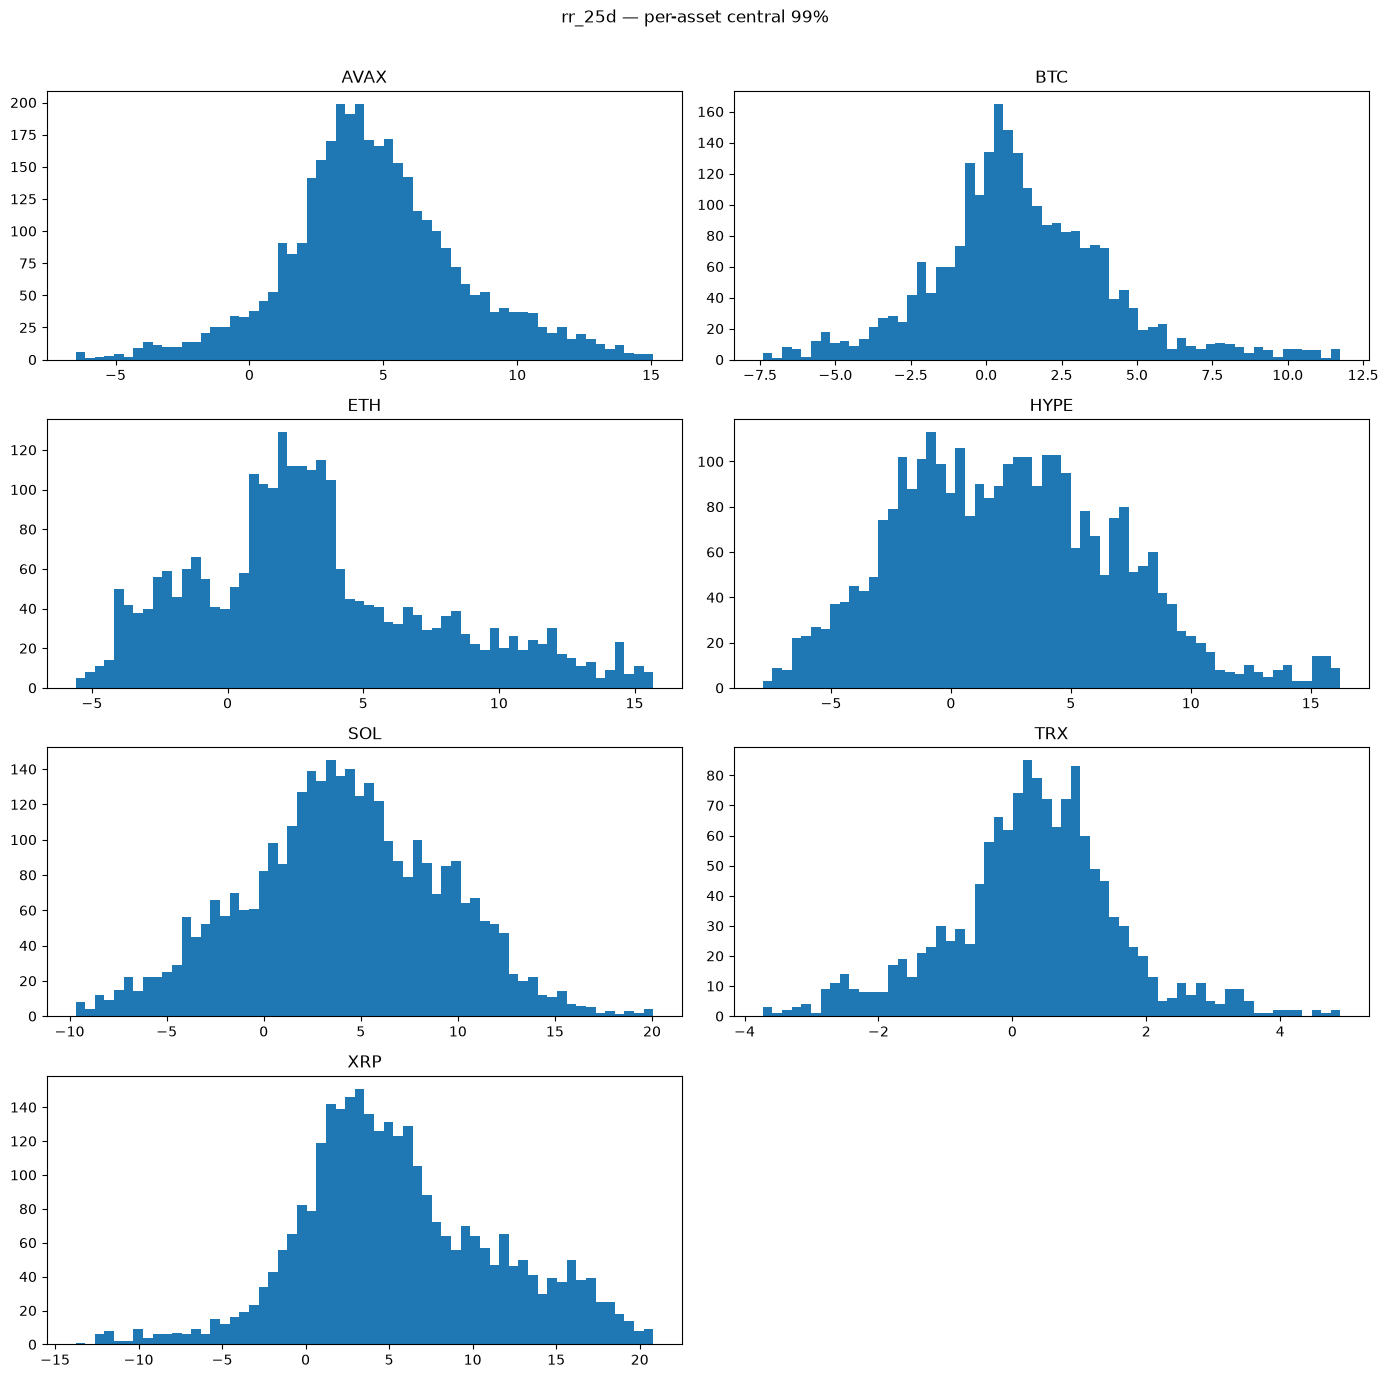

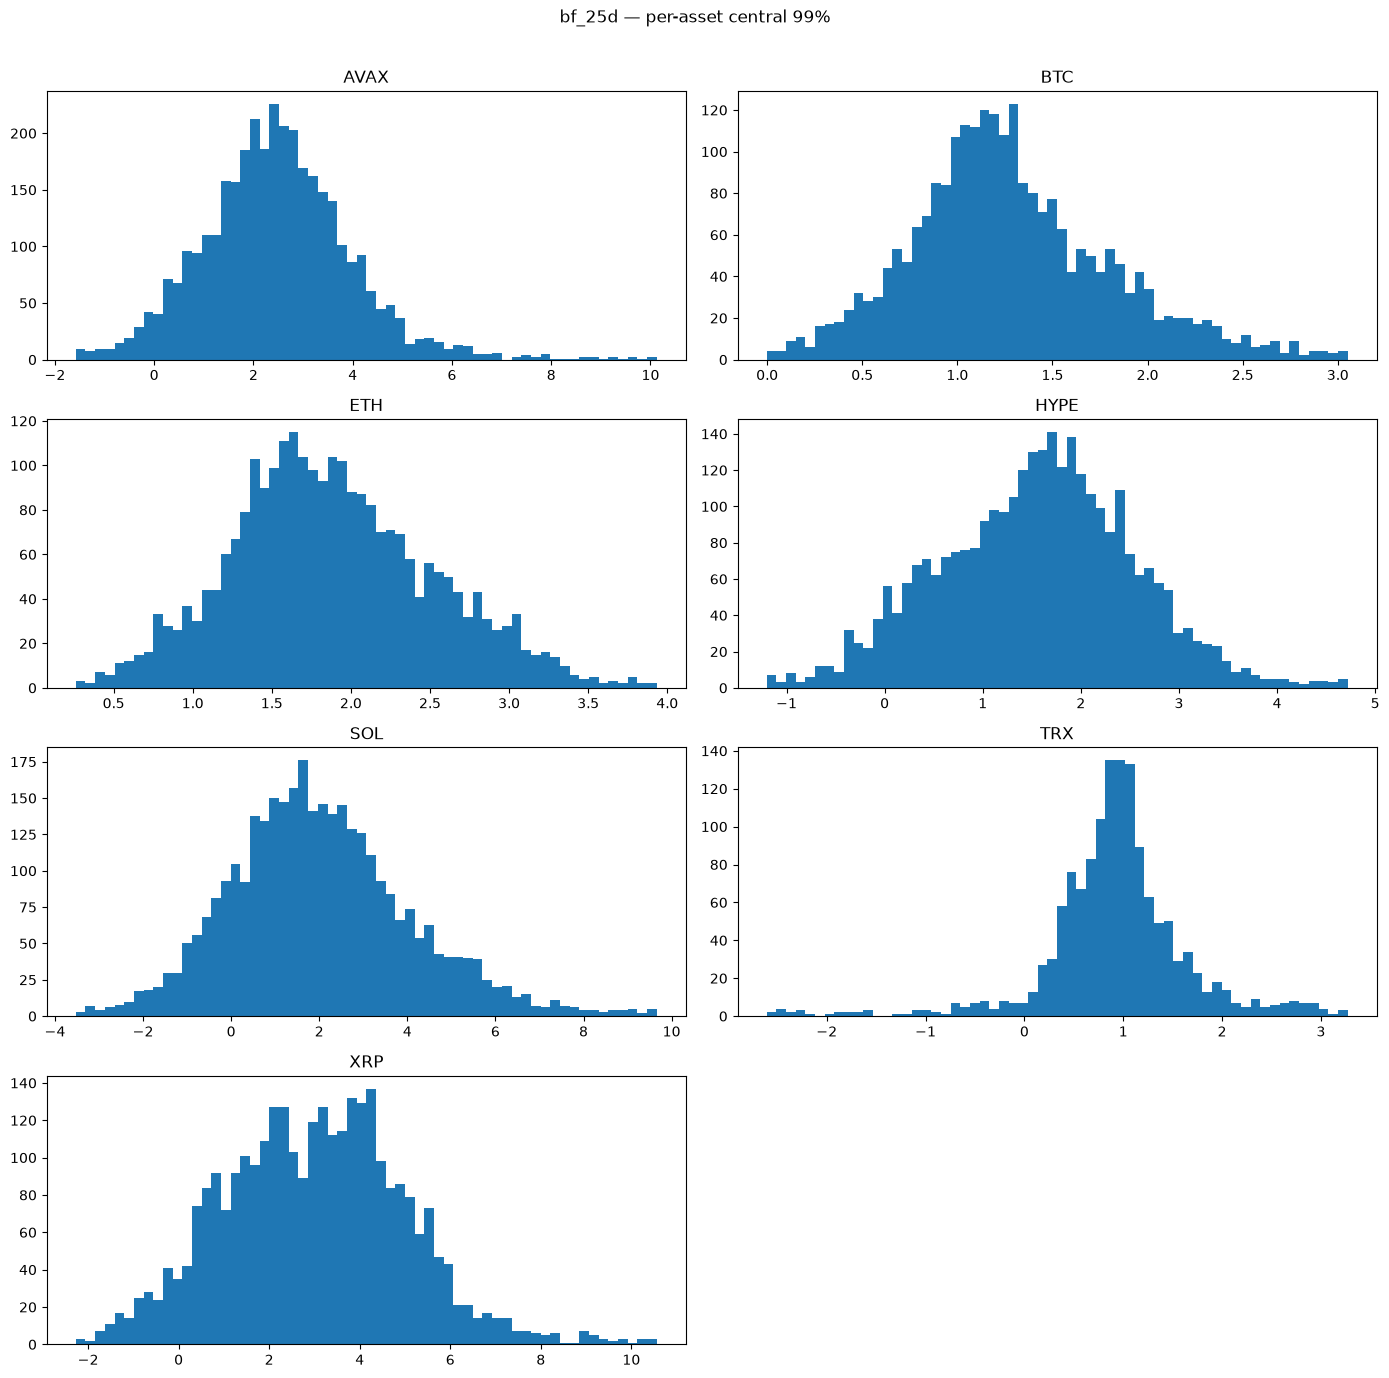

In [6]:
level_summary = feature_summary(features, OPTION_LEVEL)
level_by_asset = feature_summary(features, OPTION_LEVEL, group_col="underlying")
display(level_summary)
display(level_by_asset)

for col in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d", "bf_25d"]:
    if col in features.columns:
        plot_asset_histograms(features, col)

# Part C — Does Fixed Log-Moneyness Mean the Same Thing All Session? (audit A2)

## 6. The ±2.5% node in units of expected move

A 0DTE option's one-standard-deviation move to expiry is $\sigma_{ATM}\sqrt{\tau}$, which shrinks through the session. The fixed node $k = \pm 2.5\%$ sits at

$$
z_{2.5\%} = \frac{0.025}{\sigma_{ATM}\,\sqrt{\tau}}
$$

standard deviations from the forward. If $z_{2.5\%}$ moves from about 1 in the morning to 5–10 near expiry, `option_skew_025` measures near-ATM skew early in the session and far-wing skew late in it. Its time-of-day profile is then mostly mechanical.

Median z of the ±2.5% node, by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,5.88,3.59,2.35,1.55,1.09,0.75,0.57
BTC,18.22,10.41,6.61,4.32,3.44,2.41,1.67
ETH,14.13,8.35,5.29,3.55,2.72,1.94,1.29
HYPE,7.45,4.21,2.71,1.99,1.35,0.99,0.75
SOL,7.80,4.48,3.05,2.19,1.59,1.12,0.84
TRX,20.15,11.67,7.10,5.04,3.93,2.89,2.30
XRP,7.24,4.21,2.60,1.82,1.31,0.91,0.73


Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:


,states,beyond_2sd_pct,beyond_3sd_pct,beyond_5sd_pct
underlying,,,,
AVAX,3934,14.3,5.2,1.7
BTC,3934,77.1,51.9,21.2
ETH,3934,63.6,33.1,11.3
HYPE,3934,20.8,8.5,2.7
SOL,3934,25.1,10.0,3.0
TRX,3934,97.8,61.2,20.5
XRP,3919,17.6,7.3,2.5


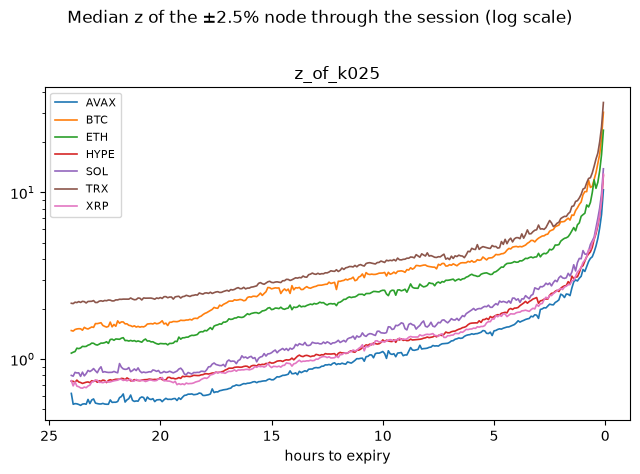

In [7]:
features["z_of_k025"] = 0.025 / features["atm_sigma_sqrt_t"]
features["z_of_k050"] = 0.050 / features["atm_sigma_sqrt_t"]

z_table = (
    features.groupby(["underlying", "tte_bucket"], observed=True)["z_of_k025"]
    .median()
    .unstack("tte_bucket")
    .round(2)
)
print("Median z of the ±2.5% node, by asset and time to expiry:")
display(z_table)

beyond = (
    features.dropna(subset=["z_of_k025"])
    .groupby("underlying")["z_of_k025"]
    .agg(
        states="count",
        beyond_2sd_pct=lambda s: 100 * (s > 2).mean(),
        beyond_3sd_pct=lambda s: 100 * (s > 3).mean(),
        beyond_5sd_pct=lambda s: 100 * (s > 5).mean(),
    )
    .round(1)
)
print("Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:")
display(beyond)

plot_median_by_tte(features, ["z_of_k025"], "Median z of the ±2.5% node through the session (log scale)", logy=True)

## 7. Mechanical drift of fixed-$k$ features

If fixed-$k$ features were stationary through the session, their median would be flat in time to expiry. The plots and the $\eta^2$ table measure how much of each feature's variance the clock bucket explains, per asset:

$$
\eta^2 = \frac{\sum_t (\bar x_{b(t)} - \bar x)^2}{\sum_t (x_t - \bar x)^2}
$$

where $\bar x_{b(t)}$ is the mean of the feature in the time-to-expiry bucket of state $t$. A high $\eta^2$ means the feature mostly encodes the clock. Part D compares this with the standardized-moneyness prototype.

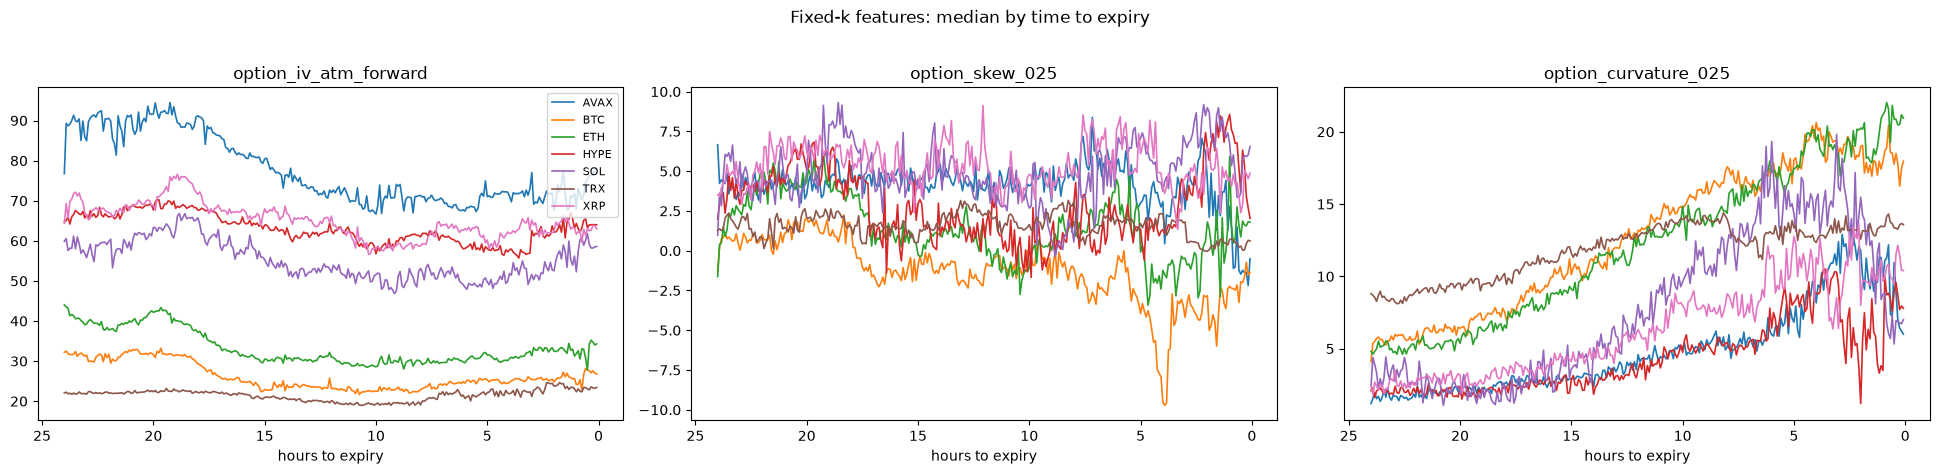

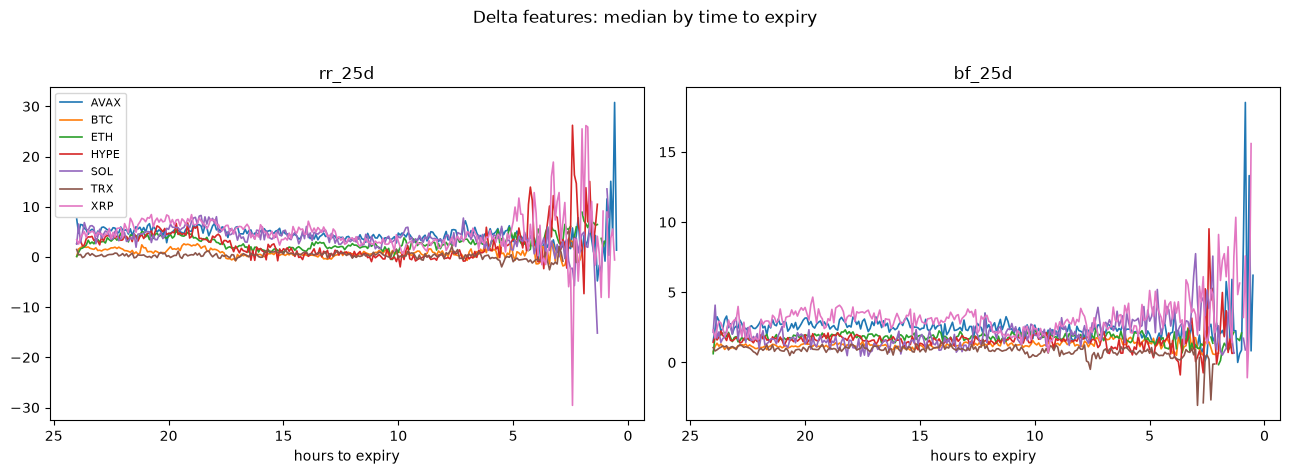

η² of the time-to-expiry bucket, per asset (fixed-k and delta features):


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
bf_10d,0.073,0.002,0.011,0.046,0.180,0.061,0.015
bf_25d,0.042,0.002,0.001,0.014,0.070,0.084,0.028
iv_call_10d,0.127,0.073,0.099,0.077,0.023,0.041,0.075
iv_call_25d,0.096,0.096,0.077,0.066,0.049,0.180,0.078
iv_put_10d,0.072,0.048,0.082,0.041,0.006,0.042,0.020
iv_put_25d,0.082,0.028,0.071,0.065,0.056,0.115,0.038
option_curvature_025,0.363,0.270,0.405,0.111,0.430,0.202,0.304
option_curvature_050,0.417,0.175,0.248,0.300,0.341,0.040,0.388
option_iv_atm_forward,0.089,0.049,0.079,0.066,0.070,0.110,0.049


In [8]:
plot_median_by_tte(
    features,
    [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025"] if c in features.columns],
    "Fixed-k features: median by time to expiry",
)
plot_median_by_tte(
    features,
    [c for c in ["rr_25d", "bf_25d"] if c in features.columns],
    "Delta features: median by time to expiry",
)

eta_rows = []
for asset, g in features.groupby("underlying"):
    for col in [c for c in OPTION_LEVEL if c in g.columns]:
        eta_rows.append({"underlying": asset, "feature": col, "eta2_tte": eta_squared(g, col)})
eta_fixed = pd.DataFrame(eta_rows).pivot(index="feature", columns="underlying", values="eta2_tte")
print("η² of the time-to-expiry bucket, per asset (fixed-k and delta features):")
display(eta_fixed.round(3))

# Part D — What the Surface Is Made Of (audit B2)

## 8. Node-level IV source

The preferred surface takes, per contract, the bid/ask IV midpoint when both sides exist, and otherwise Deribit's `mark_iv`. Each interpolated node is bracketed by two contracts. A node is classified as:

- **quote:** both bracketing contracts use the bid/ask midpoint;
- **mark:** both use Deribit's mark model;
- **mixed:** one of each.

A mark-sourced node reflects Deribit's own pricing model, not traded or quoted prices. The long-form query below joins `smile_node_state` to `normalized_option_chain` for the primary option family. It is the slowest step in the notebook.

In [9]:
nodes = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id
        FROM primary_option_surface_feature_state
    ),
    chain AS MATERIALIZED (
        SELECT n.state_id, n.instrument_name, n.preferred_iv_source
        FROM normalized_option_chain n
        JOIN prim p ON n.option_family_id = p.option_family_id
        WHERE n.surface_base_eligible
    ),
    nodes AS (
        SELECT
            s.state_id, s.state_time, s.underlying, s.session_id, s.minutes_to_expiry,
            s.option_family_id, s.target_log_moneyness, s.interpolated_iv,
            s.interpolation_span_log_moneyness,
            s.left_instrument_name, s.right_instrument_name
        FROM smile_node_state s
        JOIN prim p ON s.option_family_id = p.option_family_id
        WHERE s.surface_source = 'preferred'
          AND s.interpolated_iv IS NOT NULL
    )
    SELECT
        nodes.* EXCLUDE (left_instrument_name, right_instrument_name),
        l.preferred_iv_source AS left_source,
        r.preferred_iv_source AS right_source
    FROM nodes
    LEFT JOIN chain l ON l.state_id = nodes.state_id AND l.instrument_name = nodes.left_instrument_name
    LEFT JOIN chain r ON r.state_id = nodes.state_id AND r.instrument_name = nodes.right_instrument_name
    """,
    "preferred smile nodes with source",
)
nodes["state_time"] = pd.to_datetime(nodes["state_time"], utc=True)
is_quote = lambda s: s.eq("bid_ask_iv_mid")
nodes["node_source"] = np.select(
    [is_quote(nodes["left_source"]) & is_quote(nodes["right_source"]),
     nodes["left_source"].eq("mark_iv") & nodes["right_source"].eq("mark_iv")],
    ["quote", "mark"],
    default="mixed",
)
nodes["tte_bucket"] = pd.cut(nodes["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)

core = nodes[nodes["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
mark_share = (
    core.assign(any_mark=core["node_source"].ne("quote"))
    .groupby(["underlying", "tte_bucket"], observed=True)["any_mark"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:")
display(mark_share)

by_node = (
    nodes.assign(any_mark=nodes["node_source"].ne("quote"))
    .groupby(["underlying", "target_log_moneyness"])["any_mark"]
    .mean().mul(100).unstack("target_log_moneyness").round(1)
)
print("All nodes with at least one mark-sourced side, % — by asset and node:")
display(by_node)

print("Node source composition, all nodes:")
display(pd.crosstab(nodes["underlying"], nodes["node_source"], normalize="index").mul(100).round(1))

[preferred smile nodes with source] 186,565 rows in 18.4s
Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,98.4,92.0,67.0,40.8,10.7,2.4,3.5
BTC,100.0,95.6,79.4,65.1,52.6,28.1,11.5
ETH,100.0,96.8,77.4,63.7,40.3,11.5,2.4
HYPE,100.0,95.2,76.5,52.9,19.1,7.4,7.1
SOL,100.0,98.8,87.1,68.3,43.6,27.6,15.3
TRX,100.0,100.0,98.7,88.8,74.0,59.3,41.3
XRP,99.6,96.4,82.9,56.6,38.0,12.3,14.0


All nodes with at least one mark-sourced side, % — by asset and node:


target_log_moneyness,-0.100,-0.050,-0.025,0.000,0.025,0.050,0.100
underlying,,,,,,,
AVAX,76.4,45.2,26.1,8.6,22.4,37.5,68.1
BTC,96.6,84.6,55.1,8.6,63.1,91.5,100.0
ETH,96.9,74.6,45.2,7.8,44.5,70.3,99.1
HYPE,92.9,70.9,35.1,9.8,32.3,63.5,95.4
SOL,100.0,92.7,61.6,12.8,51.5,87.5,99.5
TRX,100.0,99.4,93.7,26.9,81.9,98.5,100.0
XRP,99.1,70.5,47.6,14.3,41.0,65.8,91.4


Node source composition, all nodes:


node_source,mark,mixed,quote
underlying,,,
AVAX,34.2,6.4,59.5
BTC,61.4,9.0,29.6
ETH,54.2,7.7,38.1
HYPE,45.7,11.5,42.9
SOL,62.2,9.5,28.3
TRX,72.9,11.5,15.6
XRP,49.8,10.2,40.0


## 9. Do source switches create artificial changes?

Consecutive states (same session, exactly 5 minutes apart) are compared at the ATM node and at the ±2.5% nodes. If the node source changes between the two states (for example quote → mark because a bid disappeared), the IV change mixes a market move with a model switch.

If the dispersion of changes with a source switch is much larger than without one, the pipeline should compute changes only when both endpoints share a source, as audit B2 proposed.

In [10]:
nd = nodes.sort_values(["underlying", "target_log_moneyness", "state_time"]).copy()
grp = nd.groupby(["underlying", "target_log_moneyness"], sort=False)
nd["prev_iv"] = grp["interpolated_iv"].shift(1)
nd["prev_source"] = grp["node_source"].shift(1)
nd["prev_time"] = grp["state_time"].shift(1)
nd["prev_session"] = grp["session_id"].shift(1)
ok = (
    (nd["state_time"] - nd["prev_time"] == pd.Timedelta(minutes=5))
    & (nd["session_id"] == nd["prev_session"])
)
nd = nd[ok].copy()
nd["d_iv"] = nd["interpolated_iv"] - nd["prev_iv"]
nd["transition"] = np.where(
    nd["node_source"] == nd["prev_source"], "same:" + nd["node_source"], "switch"
)

switch_summary = (
    nd[nd["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
    .groupby(["underlying", "transition"])["d_iv"]
    .agg(
        n="count",
        std="std",
        mad=lambda s: 1.4826 * (s - s.median()).abs().median(),
        p99_abs=lambda s: s.abs().quantile(0.99),
    )
    .round(4)
)
print("Core-node 5m IV changes by source transition:")
display(switch_summary)

switch_share = (
    nd.assign(sw=nd["transition"].eq("switch"))
    .groupby(["underlying", "tte_bucket"], observed=True)["sw"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Share of node changes that cross a source switch, % — by time to expiry:")
display(switch_share)

Core-node 5m IV changes by source transition:


n      std     mad  p99_abs
underlying transition                                
AVAX       same:mark   1497   1.8605  0.3545   8.8813
           same:mixed   364   3.2555  1.2720  12.1053
           same:quote  9232   1.7834  1.0073   7.1589
           switch       511   6.9857  2.3299  29.2083
BTC        same:mark   3358   0.6049  0.2187   2.3653
           same:mixed  1183   1.0455  0.5076   4.0464
           same:quote  6554   0.6933  0.4928   2.3550
           switch       509  18.7618  0.9986   8.8342
ETH        same:mark   2400   0.8550  0.4093   3.1868
           same:mixed   943   0.9095  0.4692   3.2596
           same:quote  7699   1.8576  0.5720   2.9568
           switch       562  13.8484  1.1078   8.9989
HYPE       same:mark   1513   1.2486  0.3129   4.5275
           same:mixed   953   3.2240  0.8638  18.4250
           same:quote  8365   4.2628  0.8386   8.9022
           switch       773  13.8809  2.2595  28.8094
SOL        same:mark   2924   1.3040  0.3869   5.4706
           same:mixed  1286   3.1210  0.9322   9.5394
           same:quote  6485   2.4938  1.8020   8.3053
           switch       909   4.7170  2.3094  20.4270
TRX        same:mark   5164   0.3157  0.0792   1.3510
           same:mixed  2429   0.6704  0.1889   2.8337
           same:quote  3671   0.6207  0.3841   2.1953
           switch       340   1.2299  0.5745   4.7696
XRP        same:mark   2310   1.4486  0.2569   6.2302
           same:mixed  1127   2.4829  0.9475   9.8877
           same:quote  7317   1.8102  1.1875   6.1637
           switch       709   4.3111  2.0084  17.8596

Share of node changes that cross a source switch, % — by time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,2.0,3.7,5.1,4.9,4.5,4.1,4.5
BTC,1.6,3.0,2.3,1.9,2.3,4.4,3.4
ETH,2.1,3.9,2.3,2.6,4.2,4.9,2.6
HYPE,0.7,4.9,5.5,6.1,6.4,7.4,6.3
SOL,1.2,4.1,3.4,3.1,4.8,6.2,5.4
TRX,0.0,0.4,0.6,1.6,1.1,1.7,2.8
XRP,1.1,2.2,3.1,5.3,4.4,5.3,5.8


# Part E — Standardized-Moneyness Prototype

## 10. Build a $z$-grid from the long-form chain

For each state of the primary family, every surface-eligible OTM contract (puts below the forward, calls above) is placed at

$$
z = \frac{\ln(K/F)}{\sigma_{ATM}\sqrt{\tau}}
$$

and IV is interpolated linearly in $k$ to the nodes $z \in \{-1, -0.5, 0, 0.5, 1\}$. As in the production grid, there is **no extrapolation**: a node exists only if strikes bracket it.

Two quality measures are kept per node:

- the interpolation span in $z$ units (near expiry, strike spacing becomes large relative to $\sigma\sqrt\tau$, so a $z$-node may sit between two distant strikes);
- whether the bracketing contracts are quote- or mark-sourced.

This is the honest trade-off of $z$-space: it fixes the meaning of each node, but near expiry the strike grid is coarse in $z$.

In [11]:
Z_NODES = [-1.0, -0.5, 0.0, 0.5, 1.0]

chain = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id FROM primary_option_surface_feature_state
    )
    SELECT
        n.state_id,
        n.log_moneyness,
        n.preferred_iv,
        n.preferred_iv_source
    FROM normalized_option_chain n
    JOIN prim p ON n.option_family_id = p.option_family_id
    WHERE n.surface_base_eligible
      AND n.preferred_iv > 0
      AND n.log_moneyness IS NOT NULL
    """,
    "long-form primary chain",
)

scale = (
    features[["state_id", "atm_sigma_sqrt_t"]]
    .dropna()
    .query("atm_sigma_sqrt_t > 0")
    .set_index("state_id")["atm_sigma_sqrt_t"]
)
chain = chain[chain["state_id"].isin(scale.index)]
chain = chain.sort_values(["state_id", "log_moneyness"]).reset_index(drop=True)
state_codes, state_index = pd.factorize(chain["state_id"], sort=False)
OFFSET = 10.0  # |log-moneyness| < 5 for any listed strike
key = state_codes * OFFSET + chain["log_moneyness"].to_numpy()
assert np.all(np.diff(key) >= 0), "chain must be sorted by state, then k"

iv = chain["preferred_iv"].to_numpy()
src_quote = chain["preferred_iv_source"].eq("bid_ask_iv_mid").to_numpy()
k_arr = chain["log_moneyness"].to_numpy()
n = len(chain)
s_state = scale.reindex(state_index).to_numpy()
codes_target = np.arange(len(state_index))

z_out = pd.DataFrame({"state_id": state_index})
for z in Z_NODES:
    k_target = z * s_state
    tkey = codes_target * OFFSET + k_target
    pos = np.searchsorted(key, tkey, side="left")
    pos_c = np.clip(pos, 0, n - 1)
    # Exact hit: compare on the state code and raw k, not on the packed key
    # (the packed key loses precision at large state codes).
    exact = (pos < n) & (state_codes[pos_c] == codes_target) & (np.abs(k_arr[pos_c] - k_target) <= 1e-12)
    right = np.where(exact, pos_c, pos)
    left = np.where(exact, pos_c, pos - 1)
    valid = (left >= 0) & (right < n)
    left_c, right_c = np.clip(left, 0, n - 1), np.clip(right, 0, n - 1)
    valid &= (state_codes[left_c] == codes_target) & (state_codes[right_c] == codes_target)
    span_k = k_arr[right_c] - k_arr[left_c]
    w = np.where(span_k > 0, (k_target - k_arr[left_c]) / np.where(span_k > 0, span_k, 1.0), 0.0)
    iv_z = iv[left_c] + w * (iv[right_c] - iv[left_c])
    tag = "00" if z == 0 else f"{z:+.1f}".replace("+", "p").replace("-", "m").replace(".", "")
    z_out[f"iv_z_{tag}"] = np.where(valid, iv_z, np.nan)
    z_out[f"span_z_{tag}"] = np.where(valid, span_k / s_state, np.nan)
    z_out[f"quote_z_{tag}"] = np.where(valid, src_quote[left_c] & src_quote[right_c], np.nan)

z_out["z_skew_05"] = z_out["iv_z_p05"] - z_out["iv_z_m05"]
z_out["z_skew_10"] = z_out["iv_z_p10"] - z_out["iv_z_m10"]
z_out["z_curv_05"] = (z_out["iv_z_p05"] + z_out["iv_z_m05"]) / 2 - z_out["iv_z_00"]
z_out["z_curv_10"] = (z_out["iv_z_p10"] + z_out["iv_z_m10"]) / 2 - z_out["iv_z_00"]
z_out["z_max_span_05"] = z_out[["span_z_m05", "span_z_00", "span_z_p05"]].max(axis=1)
z_out["z_max_span_10"] = z_out[["span_z_m10", "span_z_00", "span_z_p10"]].max(axis=1)

zf = features.merge(z_out, on="state_id", how="left")

# Consistency check: the z = 0 node must equal the pipeline's ATM IV (both are k = 0).
chk = zf[["iv_z_00", "option_iv_atm_forward"]].dropna()
diff = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs()
print(f"z=0 vs pipeline ATM IV: n={len(chk):,} | identical (<1e-6): {100 * (diff < 1e-6).mean():.2f}% | max |diff| = {diff.max():.3e}")
print("Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.")
print(f"States with a z-grid: {z_out['iv_z_00'].notna().sum():,} of {len(z_out):,}")

[long-form primary chain] 840,560 rows in 6.9s
z=0 vs pipeline ATM IV: n=27,523 | identical (<1e-6): 100.00% | max |diff| = 0.000e+00
Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.
States with a z-grid: 27,523 of 27,523


## 11. Coverage and interpolation quality of the $z$-grid

A $z$-node bracketed by strikes several $\sigma\sqrt\tau$ apart is mostly an interpolation artifact. The table reports node availability and the median span in $z$ units by time to expiry. A practical acceptance rule would be a maximum span in $z$ (for example 1.0) — the table shows what such a rule would cost.

In [12]:
z_cov = (
    zf.groupby(["underlying", "tte_bucket"], observed=True)
    .agg(
        states=("state_id", "count"),
        z05_available_pct=("z_skew_05", lambda s: 100 * s.notna().mean()),
        z10_available_pct=("z_skew_10", lambda s: 100 * s.notna().mean()),
        median_span_z05=("z_max_span_05", "median"),
        span_z05_le_1_pct=("z_max_span_05", lambda s: 100 * (s <= 1.0).mean()),
        quote_atm_pct=("quote_z_00", lambda s: 100 * s.mean()),
    )
    .round(2)
)
display(z_cov)

kcov = (
    features.assign(core=as_bool(features["core_smile_usable"]) if "core_smile_usable" in features.columns else False)
    .groupby(["underlying", "tte_bucket"], observed=True)["core"].mean().mul(100).round(1)
    .unstack("tte_bucket")
)
print("For comparison — fixed-k core usable (%):")
display(kcov)

states  z05_available_pct  z10_available_pct  median_span_z05  span_z05_le_1_pct  quote_atm_pct
underlying tte_bucket                                                                                                    
AVAX       ≤30m (settle)      96              87.50              87.50             2.28               1.04           4.76
           30m–1h             96              86.46              86.46             1.41               7.29          24.10
           1–3h              384              86.20              86.20             0.91              57.81          62.84
           3–6h              576              87.15              87.15             0.61              81.94          95.62
           6–12h            1152              86.37              86.37             0.46              86.37          98.79
           12–18h           1152              86.28              86.28             0.32              86.28          99.09
           18–24h           1152              82.03              82.03             0.24              82.03          96.93
BTC        ≤30m (settle)      96              87.50              87.50             4.38               0.00           0.00
           30m–1h             96              86.46              86.46             2.75               0.00          13.25
           1–3h              384              86.20              86.20             1.79               1.56          58.31
           3–6h              576              87.15              87.15             1.13              31.60          94.82
           6–12h            1152              86.37              86.37             0.85              59.20          99.70
           12–18h           1152              86.28              86.28             0.61              76.65          99.90
           18–24h           1152              81.94              81.94             0.42              78.91          98.41
ETH        ≤30m (settle)      96              87.50              87.50             4.27               0.00           0.00
           30m–1h             96              86.46              86.46             2.52               1.04           9.64
           1–3h              384              86.20              86.20             1.61               2.60          67.07
           3–6h              576              87.15              87.15             1.12              31.60          95.82
           6–12h            1152              86.37              86.37             0.84              64.76         100.00
           12–18h           1152              86.28              86.28             0.60              85.16          99.80
           18–24h           1152              82.03              81.94             0.40              82.03          98.41
HYPE       ≤30m (settle)      96              87.50              87.50             3.23               0.00           0.00
           30m–1h             96              86.46              86.46             1.87               0.00          13.25
           1–3h              384              86.20              86.20             1.24              12.76          58.61
           3–6h              576              87.15              87.15             0.92              53.47          89.64
           6–12h            1152              86.37              86.37             0.62              77.69          98.79
           12–18h           1152              86.28              86.28             0.45              86.28          99.80
           18–24h           1152              82.03              82.03             0.35              82.03          97.35
SOL        ≤30m (settle)      96              87.50              87.50             2.72               0.00           0.00
           30m–1h             96              86.46              86.46             1.64               2.08           3.61
           1–3h              384              86.20              86.20             1.07              30.99          37.46


For comparison — fixed-k core usable (%):


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,87.5,86.5,86.2,87.2,86.4,86.3,82.0
BTC,87.5,86.5,86.2,87.2,86.4,86.3,82.0
ETH,87.5,86.5,86.2,87.2,86.4,86.3,82.0
HYPE,87.5,86.5,86.2,87.2,86.4,86.3,82.0
SOL,87.5,86.5,86.2,87.2,86.4,86.3,82.0
TRX,87.5,86.5,86.2,87.2,86.4,86.3,82.0
XRP,87.5,86.5,82.0,81.1,80.6,86.2,82.0


## 12. Is the $z$-grid more stationary through the session?

The same $\eta^2$ diagnostic as Section 7, now comparing fixed-$k$ and $z$ features on the states where both exist. Skew and curvature are also shown **relative to ATM IV**, because ATM IV itself has an intraday profile.

Reading the result:

- if $z$-features have clearly lower $\eta^2$ than their fixed-$k$ counterparts, the fixed-$k$ grid is mostly measuring the clock and audit A2 holds;
- if they are similar, the fixed-$k$ grid is not the main source of TTE dependence, and the remaining profile is genuine intraday seasonality (to be removed by the clock baseline in the framework's Step 2).

,underlying,measure,n_both,eta2_fixed_k,eta2_z,z_minus_k
0,AVAX,skew,3934,0.004,0.103,0.099
1,AVAX,curvature,3934,0.363,0.036,-0.327
2,AVAX,skew / ATM,3934,0.007,0.082,0.075
3,AVAX,curvature / ATM,3934,0.328,0.034,-0.293
4,BTC,skew,3933,0.084,0.050,-0.033
5,BTC,curvature,3933,0.562,0.040,-0.522
6,BTC,skew / ATM,3933,0.054,0.051,-0.003
7,BTC,curvature / ATM,3933,0.258,0.052,-0.206
8,ETH,skew,3934,0.024,0.049,0.025
9,ETH,curvature,3934,0.405,0.002,-0.403


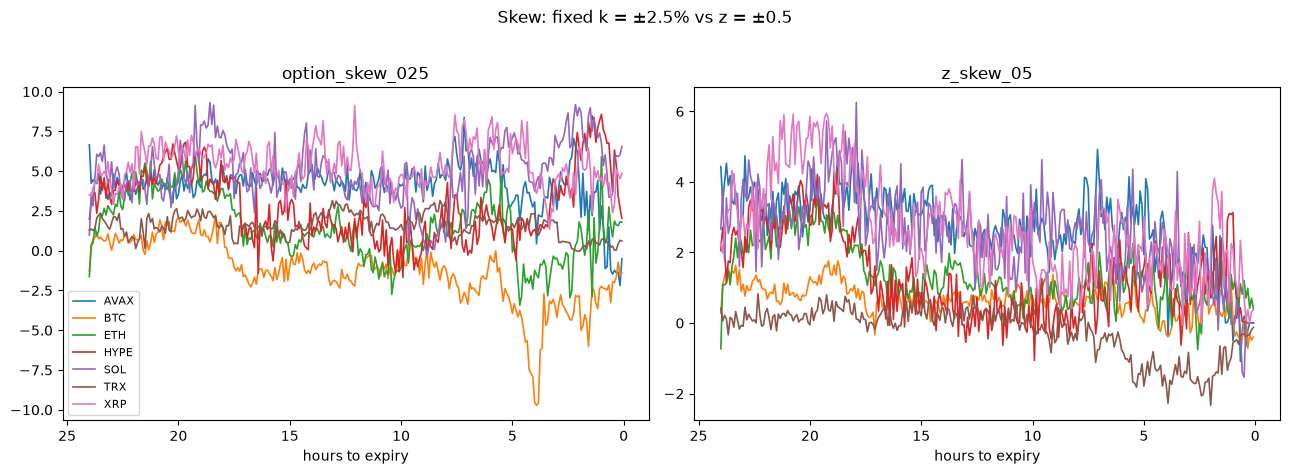

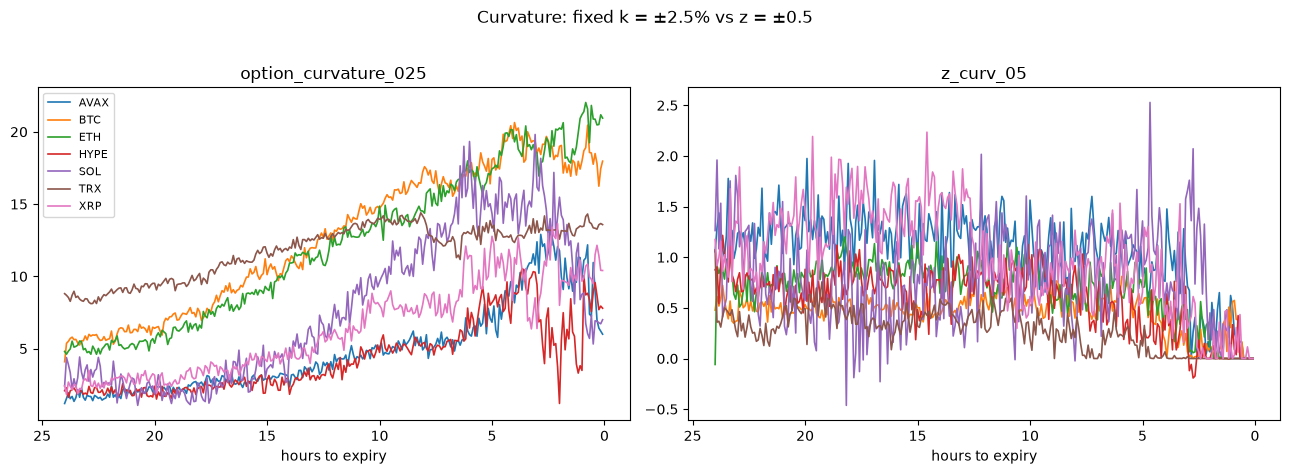

In [13]:
zf["skew_025_rel"] = zf["option_skew_025"] / zf["option_iv_atm_forward"]
zf["curv_025_rel"] = zf["option_curvature_025"] / zf["option_iv_atm_forward"]
zf["z_skew_05_rel"] = zf["z_skew_05"] / zf["option_iv_atm_forward"]
zf["z_curv_05_rel"] = zf["z_curv_05"] / zf["option_iv_atm_forward"]

PAIRS = [
    ("skew", "option_skew_025", "z_skew_05"),
    ("curvature", "option_curvature_025", "z_curv_05"),
    ("skew / ATM", "skew_025_rel", "z_skew_05_rel"),
    ("curvature / ATM", "curv_025_rel", "z_curv_05_rel"),
]

rows = []
for asset, g in zf.groupby("underlying"):
    for label, kcol, zcol in PAIRS:
        both = g.dropna(subset=[kcol, zcol])
        rows.append({
            "underlying": asset, "measure": label, "n_both": len(both),
            "eta2_fixed_k": eta_squared(both, kcol),
            "eta2_z": eta_squared(both, zcol),
        })
stationarity = pd.DataFrame(rows)
stationarity["z_minus_k"] = stationarity["eta2_z"] - stationarity["eta2_fixed_k"]
display(stationarity.round(3))

plot_median_by_tte(zf, ["option_skew_025", "z_skew_05"], "Skew: fixed k = ±2.5% vs z = ±0.5")
plot_median_by_tte(zf, ["option_curvature_025", "z_curv_05"], "Curvature: fixed k = ±2.5% vs z = ±0.5")

# Part F — Dynamics

## 13. Surface-change distributions and the settlement window (audit B4)

Deribit daily options settle to the 30-minute TWAP of the index from 07:30 to 08:00 UTC. During the last six states (`minutes_to_expiry ≤ 30`) part of the settlement price is already fixed, so quotes and implied volatilities stop behaving like those of a European option. The comparison below shows whether level and change distributions break inside that window.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,atm_iv_change_5m,3868,16.059028,-0.027113,2.353841,-0.078565,55.196628,-34.218765,-17.687319,-6.062586,-2.513855,-0.024558,2.561681,6.552225,19.777876,32.712240
1,AVAX,atm_iv_change_15m,3837,16.731771,-0.077973,3.047945,0.858932,29.480377,-33.548225,-23.973901,-8.096462,-3.788274,-0.140986,3.879280,9.257140,27.155395,37.388575
2,AVAX,atm_iv_change_1h,3704,19.618056,-0.395263,4.571997,1.918491,19.032516,-22.739299,-21.354083,-11.362672,-6.267782,-0.564580,6.891456,12.499869,39.103873,51.520807
3,AVAX,skew_025_change_5m,3868,16.059028,-0.001400,3.018315,-0.491205,35.997870,-50.283305,-18.170835,-8.613284,-3.811237,-0.018507,3.954784,9.167236,19.833292,38.133247
4,AVAX,skew_025_change_15m,3837,16.731771,0.005812,4.352116,0.514997,36.111818,-51.151493,-30.403074,-11.763893,-5.048718,0.000000,5.269898,12.192228,38.069752,56.012830
5,AVAX,skew_025_change_1h,3704,19.618056,-0.053733,6.547972,-0.471650,15.541947,-66.284501,-45.637134,-21.870772,-8.289274,-0.000854,8.419463,21.050039,42.466545,46.700594
6,AVAX,curvature_025_change_5m,3868,16.059028,0.033728,2.396540,-0.094821,67.566857,-33.576139,-23.861846,-5.912644,-2.404584,0.029707,2.434485,5.814385,24.666404,36.339965
7,AVAX,curvature_025_change_15m,3837,16.731771,0.096573,3.026809,-1.041218,44.296367,-39.907683,-28.576662,-8.514832,-2.863346,0.121387,3.232608,8.292452,26.796267,35.315394
8,AVAX,curvature_025_change_1h,3704,19.618056,0.431087,4.298979,-0.397943,19.960670,-43.219400,-32.422473,-12.489587,-4.504685,0.330794,5.766507,14.796856,29.041709,33.534273
9,AVAX,skew_050_change_5m,3868,16.059028,0.000567,3.756301,-0.855883,31.152132,-53.443394,-25.142160,-10.766724,-5.283522,0.000000,5.346431,10.199733,20.195783,50.896840


median_abs                                            p99_abs                                  
segment                          1h before window rest of session settlement window 1h before window rest of session settlement window
feature               underlying                                                                                                      
atm_iv_change_5m      AVAX                  1.006           0.621             0.334           11.616           7.212            32.968
                      BTC                   0.843           0.327             0.659            6.305           2.561            10.961
                      ETH                   0.874           0.373             0.408            9.002           3.033            12.089
                      HYPE                  1.753           0.580             0.049           19.432           8.765            19.203
                      SOL                   1.564           1.284             0.298           21.800           9.146            46.190
                      TRX                   0.093           0.281             0.096            1.726           3.112             1.395
                      XRP                   1.053           0.691             0.432           14.676           6.790            28.724
option_iv_atm_forward AVAX                 69.370          77.994            76.732          110.207         117.048           133.094
                      BTC                  25.874          24.964            27.096           37.100          47.613            43.829
                      ETH                  32.018          32.241            34.182           40.735          58.585            42.221
                      HYPE                 64.284          62.136            63.989           87.394          76.368            88.185
                      SOL                  56.567          53.749            58.966          100.932          84.448           147.920
                      TRX                  22.934          21.449            22.871           36.246          30.563            28.805
                      XRP                  61.694          64.926            62.575          123.836         105.538           128.728
skew_025_change_5m    AVAX                  0.963           1.036             0.971           19.425          11.070            15.867
                      BTC                   0.314           0.424             0.321            3.834           3.948             3.544
                      ETH                   0.610           0.548             0.451            4.195           4.513             7.234
                      HYPE                  0.535           0.931             0.614          183.112          14.900             8.657
                      SOL                   0.618           1.189             0.544            7.550           9.765             5.909
                      TRX                   0.071           0.180             0.062            1.020           2.633             0.962
                      XRP                   1.230           1.053             1.038           21.164           9.917             6.617

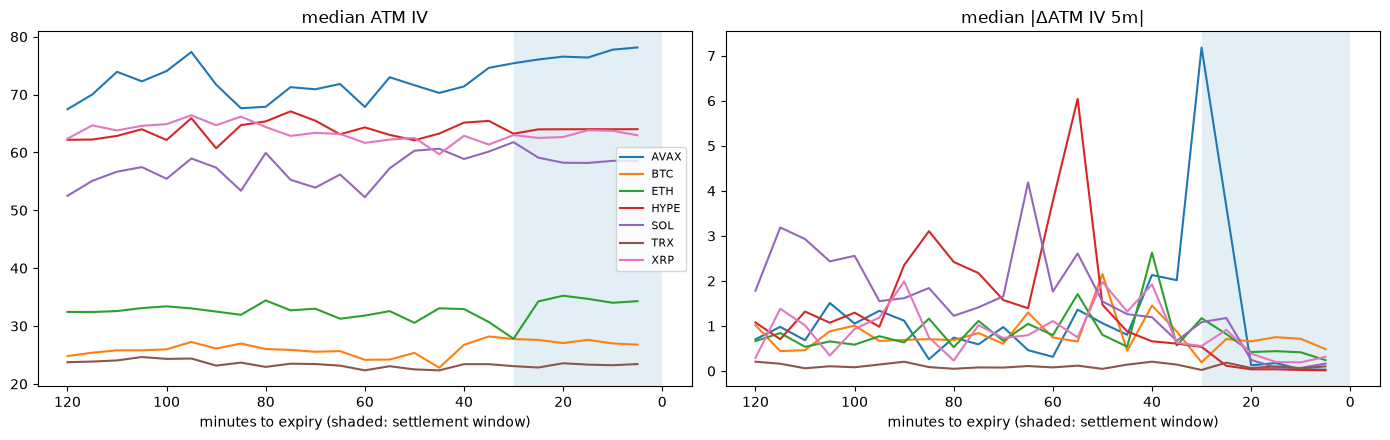

In [14]:
dyn_summary = feature_summary(features, OPTION_DYNAMIC, group_col="underlying")
display(dyn_summary)

settle_rows = []
for asset, g in features.groupby("underlying"):
    for col in ["option_iv_atm_forward", "atm_iv_change_5m", "skew_025_change_5m"]:
        if col not in g.columns:
            continue
        for label, part in [("settlement window", g[g["in_settlement_window"]]),
                            ("1h before window", g[g["minutes_to_expiry"].between(35, 90)]),
                            ("rest of session", g[g["minutes_to_expiry"] > 90])]:
            s = clean_numeric(part, col)
            settle_rows.append({
                "underlying": asset, "feature": col, "segment": label, "n": len(s),
                "median": s.median() if len(s) else np.nan,
                "median_abs": s.abs().median() if len(s) else np.nan,
                "p99_abs": s.abs().quantile(0.99) if len(s) else np.nan,
            })
settlement = pd.DataFrame(settle_rows)
display(settlement.pivot_table(index=["feature", "underlying"], columns="segment", values=["median_abs", "p99_abs"]).round(3))

last = features[features["minutes_to_expiry"] <= 120]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for asset, g in last.groupby("underlying"):
    m = g.groupby("minutes_to_expiry")["option_iv_atm_forward"].median().sort_index(ascending=False)
    axes[0].plot(m.index, m.values, label=asset)
    if "atm_iv_change_5m" in g.columns:
        a = g.groupby("minutes_to_expiry")["atm_iv_change_5m"].apply(lambda s: s.abs().median()).sort_index(ascending=False)
        axes[1].plot(a.index, a.values, label=asset)
for ax, title in zip(axes, ["median ATM IV", "median |ΔATM IV 5m|"]):
    ax.axvspan(0, 30, alpha=0.12)
    ax.invert_xaxis()
    ax.set_xlabel("minutes to expiry (shaded: settlement window)")
    ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14. Persistence within the session

Level features that are persistent are candidate **structural** inputs; changes with near-zero autocorrelation behave like innovations. All autocorrelations are computed on the exact 5-minute grid and never cross the 08:00 boundary.

lag_minutes                         5      30     60     120
feature               underlying                            
atm_iv_change_5m      AVAX       -0.308  0.000 -0.032  0.001
                      BTC        -0.022  0.012  0.007 -0.002
                      ETH         0.003  0.053  0.011 -0.024
                      HYPE       -0.363 -0.027  0.014  0.024
                      SOL        -0.310 -0.017 -0.002  0.004
                      TRX        -0.347  0.063 -0.022 -0.003
                      XRP        -0.258 -0.009 -0.021  0.015
option_curvature_025  AVAX        0.913  0.800  0.699  0.495
                      BTC         0.678  0.654  0.628  0.574
                      ETH         0.858  0.840  0.823  0.792
                      HYPE        0.880  0.676  0.659  0.570
                      SOL         0.890  0.806  0.748  0.660
                      TRX         0.986  0.958  0.925  0.867
                      XRP         0.939  0.847  0.786  0.671
option_iv_atm_forward AVAX        0.991  0.979  0.967  0.949
                      BTC         0.761  0.742  0.724  0.687
                      ETH         0.869  0.854  0.838  0.804
                      HYPE        0.978  0.957  0.943  0.909
                      SOL         0.966  0.935  0.907  0.872
                      TRX         0.979  0.939  0.893  0.818
                      XRP         0.992  0.972  0.952  0.911
option_skew_025       AVAX        0.920  0.745  0.596  0.425
                      BTC         0.983  0.924  0.869  0.751
                      ETH         0.949  0.900  0.846  0.759
                      HYPE        0.865  0.589  0.605  0.505
                      SOL         0.932  0.817  0.745  0.599
                      TRX         0.990  0.943  0.868  0.681
                      XRP         0.933  0.816  0.711  0.533
rr_25d                AVAX        0.717  0.543  0.447  0.407
                      BTC         0.302  0.269  0.261  0.240
                      ETH         0.759  0.743  0.728  0.693
                      HYPE        0.888  0.833  0.789  0.678
                      SOL         0.837  0.745  0.672  0.580
                      TRX         0.757  0.505  0.385  0.272
                      XRP         0.922  0.832  0.767  0.611
skew_025_change_5m    AVAX       -0.214  0.010 -0.083  0.001
                      BTC        -0.085  0.023 -0.041  0.031
                      ETH        -0.033 -0.025  0.012  0.033
                      HYPE       -0.260 -0.033  0.030 -0.085
                      SOL        -0.262 -0.058  0.018 -0.015
                      TRX        -0.085  0.048  0.020 -0.027
                      XRP        -0.245 -0.025 -0.069 -0.047
z_curv_05             AVAX        0.514  0.358  0.264  0.223
                      BTC         0.651  0.376  0.284  0.201
                      ETH         0.086  0.071  0.046  0.039
                      HYPE        0.557  0.366  0.320  0.218
                      SOL         0.390  0.220  0.136  0.058
                      TRX         0.760  0.544  0.371  0.234
                      XRP         0.744  0.451  0.340  0.298
z_skew_05             AVAX        0.623  0.492  0.428  0.370
                      BTC         0.944  0.871  0.822  0.742
                      ETH         0.966  0.926  0.896  0.854
                      HYPE        0.810  0.721  0.634  0.520
                      SOL         0.680  0.551  0.459  0.357
                      TRX         0.908  0.775  0.645  0.439
                      XRP         0.840  0.692  0.613  0.489

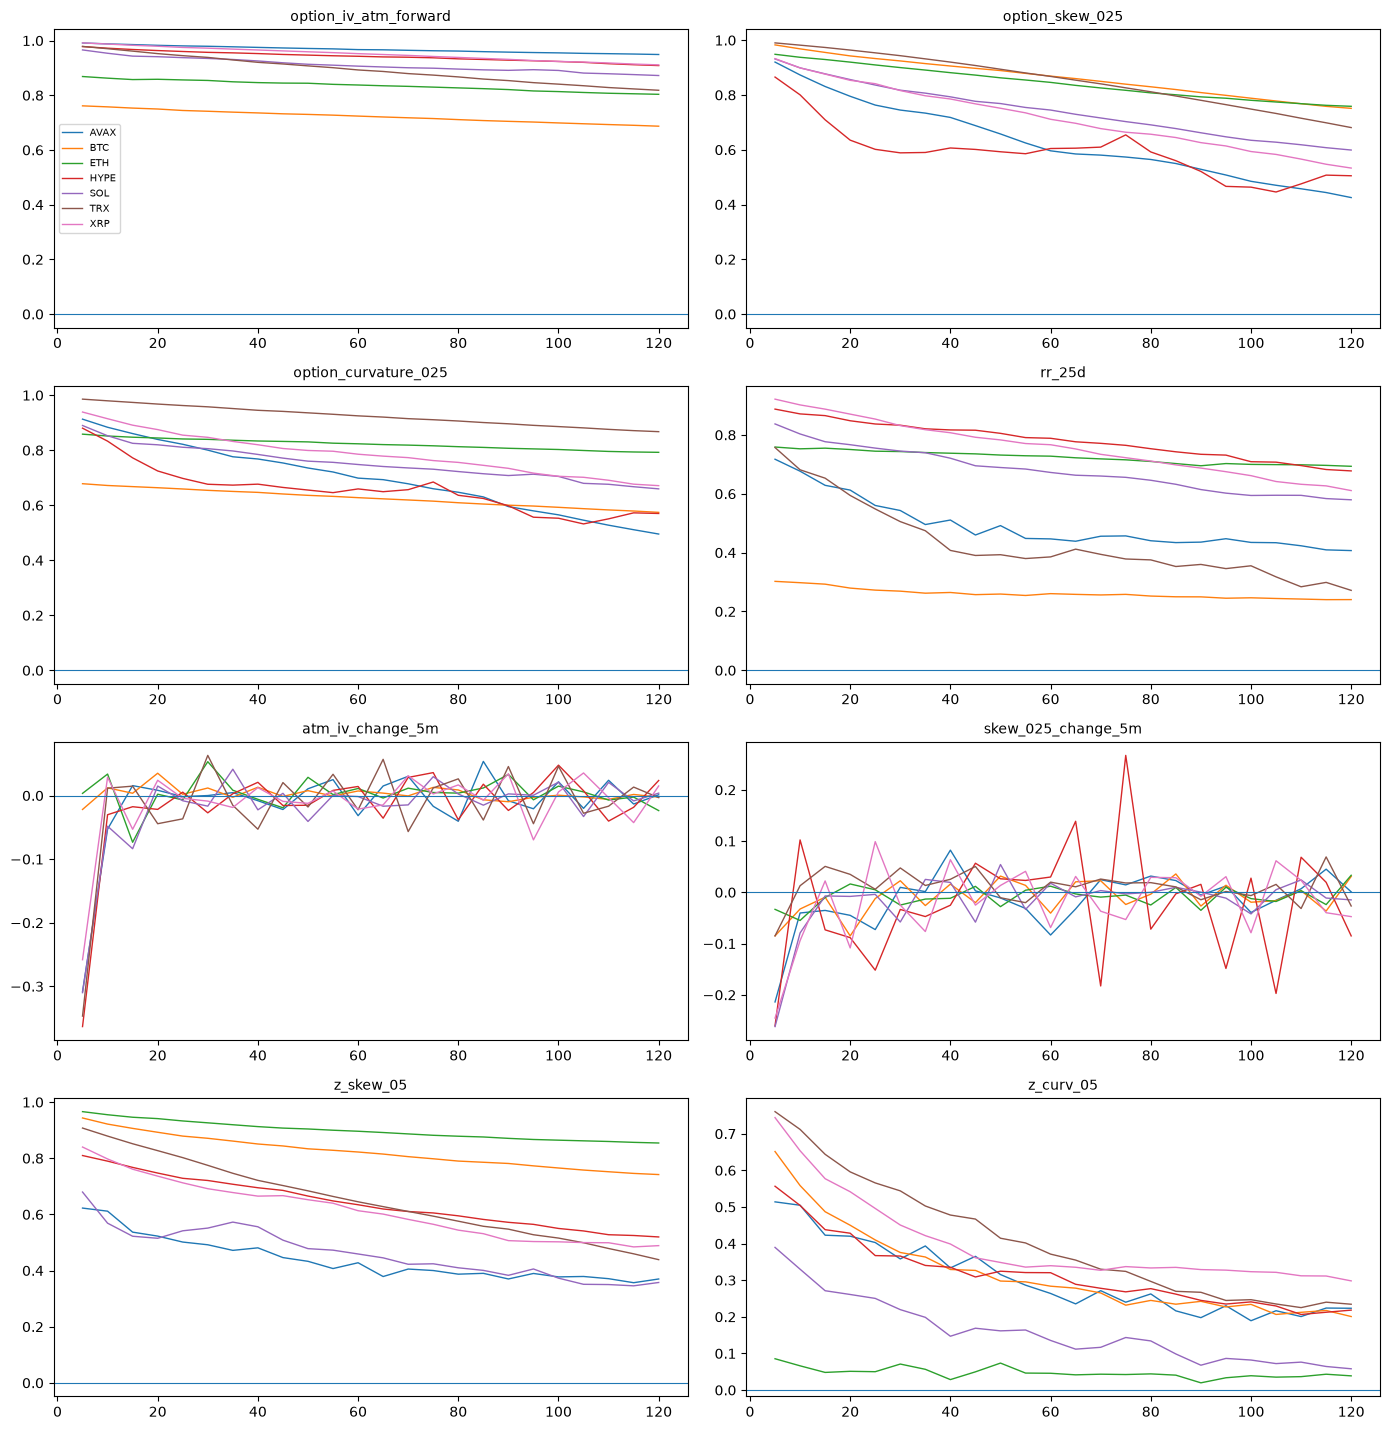

In [15]:
acf_frames = []
for col in [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d",
                        "atm_iv_change_5m", "skew_025_change_5m"] if c in features.columns]:
    acf_frames.append(within_session_acf(features, col, max_lag=24))
for col in ["z_skew_05", "z_curv_05"]:
    acf_frames.append(within_session_acf(zf, col, max_lag=24))
option_acf = pd.concat(acf_frames, ignore_index=True)

summary_lags = [5, 30, 60, 120]
display(
    option_acf[option_acf["lag_minutes"].isin(summary_lags)]
    .pivot_table(index=["feature", "underlying"], columns="lag_minutes", values="acf")
    .round(3)
)

feats = option_acf["feature"].unique()
fig, axes = plt.subplots(math.ceil(len(feats) / 2), 2, figsize=(14, 3.6 * math.ceil(len(feats) / 2)))
for ax, feat in zip(np.atleast_1d(axes).ravel(), feats):
    for asset, g in option_acf[option_acf["feature"] == feat].groupby("underlying"):
        ax.plot(g["lag_minutes"], g["acf"], linewidth=1, label=asset)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(feat, fontsize=10)
np.atleast_1d(axes).ravel()[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part G — Robustness

## 15. Linear USDC vs inverse families (BTC, ETH)

BTC and ETH list both linear USDC and inverse options for the same expiry. The primary family is linear USDC. If both families give the same ATM IV and the same changes, the primary-family choice is harmless; a persistent gap or weak change correlation would mean one family's surface is dominated by stale or mark-sourced quotes.

In [16]:
fam_cols = relation_columns("option_surface_feature_state")
if {"iv_atm_forward", "option_family_id", "state_id"}.issubset(fam_cols):
    fam = q(
        """
        SELECT state_id, state_time, underlying, option_family_id, instrument_type,
               iv_atm_forward, atm_iv_change_5m
        FROM option_surface_feature_state
        WHERE underlying IN ('BTC', 'ETH')
        """,
        "BTC/ETH families",
    )
    fam["family"] = np.where(fam["instrument_type"].str.lower().eq("linear"), "linear", "inverse")
    wide = fam.pivot_table(index=["underlying", "state_id"], columns="family",
                           values=["iv_atm_forward", "atm_iv_change_5m"], aggfunc="first")
    if {("iv_atm_forward", "linear"), ("iv_atm_forward", "inverse")}.issubset(wide.columns):
        wide["atm_gap"] = wide[("iv_atm_forward", "linear")] - wide[("iv_atm_forward", "inverse")]
        out = []
        for asset, g in wide.groupby(level="underlying"):
            ch = g[[("atm_iv_change_5m", "linear"), ("atm_iv_change_5m", "inverse")]].dropna()
            out.append({
                "underlying": asset,
                "states_both": int(g["atm_gap"].notna().sum()),
                "median_gap": g["atm_gap"].median(),
                "mad_gap": 1.4826 * (g["atm_gap"] - g["atm_gap"].median()).abs().median(),
                "p99_abs_gap": g["atm_gap"].abs().quantile(0.99),
                "corr_5m_changes": ch.corr().iloc[0, 1] if len(ch) > 20 else np.nan,
            })
        family_comparison = pd.DataFrame(out)
        display(family_comparison.round(4))
    else:
        family_comparison = pd.DataFrame()
        print("Only one family present for BTC/ETH; comparison skipped.")
else:
    family_comparison = pd.DataFrame()
    print("option_surface_feature_state lacks the needed columns; comparison skipped.")

[BTC/ETH families] 17,000 rows in 0.0s


,underlying,states_both,median_gap,mad_gap,p99_abs_gap,corr_5m_changes
0,BTC,3934,-0.3096,0.5715,3.2194,0.0435
1,ETH,3934,0.2018,0.6319,2.7373,0.1254


## 16. Level drift across sessions

Median ATM IV and skew per session. Large session-to-session level shifts are expected in crypto (volatility regimes); they matter here because any later normalization must be fitted on training history only.

option_iv_atm_forward                                                 option_skew_025                                              rr_25d                                             
underlying                   AVAX     BTC     ETH    HYPE     SOL     TRX     XRP            AVAX    BTC     ETH   HYPE     SOL    TRX     XRP   AVAX    BTC     ETH   HYPE     SOL    TRX     XRP
expiry_date                                                                                                                                                                                       
2026-09-20                    NaN     NaN     NaN     NaN     NaN     NaN     NaN             NaN    NaN     NaN    NaN     NaN    NaN     NaN    NaN    NaN     NaN    NaN     NaN    NaN     NaN
2026-09-21                    NaN     NaN     NaN     NaN     NaN     NaN     NaN             NaN    NaN     NaN    NaN     NaN    NaN     NaN    NaN    NaN     NaN    NaN     NaN    NaN     NaN
2026-09-22                 91.483  35.202  50.258  64.781  79.975  22.688  83.393           5.460  1.882  16.137  7.055  10.445  2.460   9.143  6.520  5.064  12.148  5.586  10.555    NaN  11.076
2026-09-23                 90.904  30.883  43.151  70.250  63.046  22.586  89.174           4.936  5.419  12.673  9.864  10.141  6.156  11.218  6.649  5.631   8.738  9.605   9.726  2.899  13.081
2026-09-24                 93.187  26.423  34.783  65.455  61.031  25.546  70.116           2.777 -5.383   6.324 -2.997   2.784  4.198   0.075  3.804 -0.857   3.857 -0.557   4.324  2.666   0.963
2026-09-25                 89.913  34.125  38.014  67.690  61.103  23.105  69.851           2.245 -8.991  -4.484  0.306   3.031  1.476   0.952  3.320 -3.457  -2.973 -0.021   6.260  0.083   1.870
2026-09-26                 68.058  18.690  24.913  50.663  47.757  23.076  66.579           5.568  4.719   2.416  2.146   5.616  1.579   2.736  5.811  2.861   3.187  2.046   4.287 -0.228   3.469
2026-09-27                 55.207  13.812  22.803  43.399  41.148  18.668  55.577           4.372 -0.472   0.979  7.463   1.885 -4.487   5.207  4.277  1.471   1.481  3.755   2.836    NaN   1.489
2026-09-28                 67.786  24.414  32.389  54.755  53.435  22.074  66.406           4.771 -0.235   4.286  0.740  12.260 -0.058  11.681  5.120  3.283   3.611  1.200   8.185    NaN  11.198
2026-09-29                 77.373  24.526  33.735  62.933  57.110  21.302  65.869           4.017 -5.976  -2.615  0.312  -2.326 -1.696   5.391  4.022 -1.249  -1.120 -0.701  -3.477    NaN   2.662
2026-09-30                 87.359  24.484  33.797  66.521  56.981  19.615  69.671           2.609 -1.017   1.352 -1.074   3.870  0.848   6.536  3.024  0.739   2.609 -0.906   4.249  0.577   6.700
2026-10-01                 79.854  26.021  30.881  67.759  53.397  19.995  59.354           4.611  0.223   2.539  4.985  -0.013 -0.088   3.828  4.080  0.653   0.827  4.432  -0.117  0.872   2.668
2026-10-02                 70.700  26.749  30.868  65.595  52.453  20.068  62.370           4.549  0.119   5.383  0.881   1.025  1.830   5.786  3.781  0.849   2.729  1.171   0.555 -0.001   3.599
2026-10-03                 60.038  18.358  21.918  48.014  42.045  18.951  51.804           8.610  3.002  -7.746  5.730   6.584  7.173   6.968  6.264  1.378   6.931  2.988   3.757  0.117   6.010
2026-10-04                 42.071  14.079  19.109  39.969  36.185  15.070  37.156           2.602 -1.040  -4.723  0.599   4.864  3.472   4.820  2.339  0.018  -2.454 -0.273   2.878  0.229   4.348
2026-10-05                 61.350  21.881  25.679  51.719  44.250  20.465  45.547           4.073 -2.180  -2.406 -1.637   6.027  1.307   9.372  3.613  0.167  -1.815  0.725   4.256  0.805   5.742

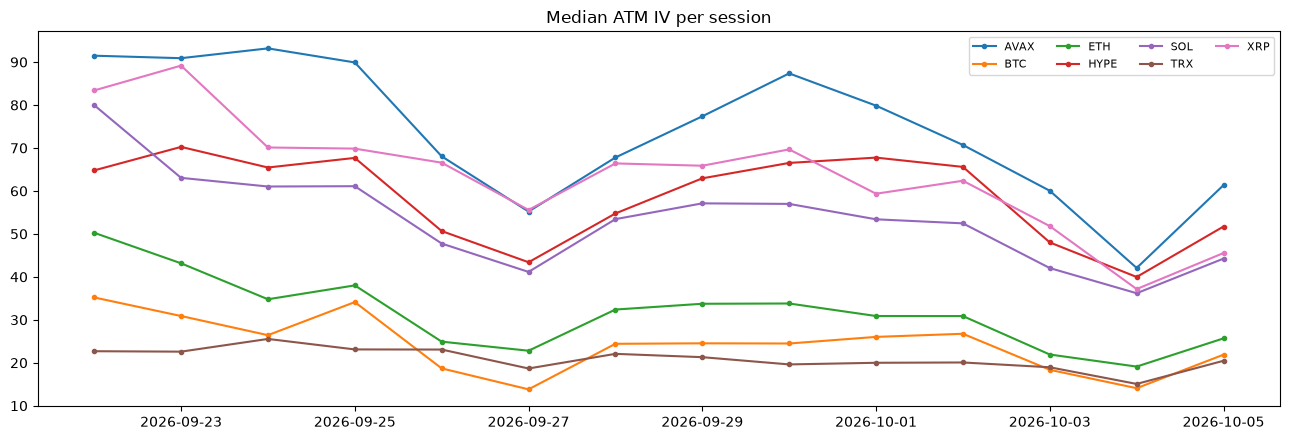

In [17]:
session_levels = (
    features.groupby(["expiry_date", "underlying"])[
        [c for c in ["option_iv_atm_forward", "option_skew_025", "rr_25d"] if c in features.columns]
    ]
    .median()
    .unstack("underlying")
)
display(session_levels.round(3))

fig, ax = plt.subplots(figsize=(13, 4.5))
for asset in ASSETS:
    s = features[features["underlying"] == asset].groupby("expiry_date")["option_iv_atm_forward"].median()
    ax.plot(s.index, s.values, marker="o", ms=3, label=asset)
ax.set_title("Median ATM IV per session")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

# Part H — Research Handoff

## 17. Interpretation checklist

Answer these before Notebook 04:

1. **B1:** how many valid option states does the futures gate remove, and on which dates? Is decoupling surface eligibility from the futures stream justified?
2. **A2:** how far does the ±2.5% node travel in $z$ through the session, and for which assets is it beyond 3σ for most of the day?
3. **A2:** do $z$-space skew and curvature have materially lower $\eta^2$ than the fixed-$k$ versions? For which assets?
4. **A2 trade-off:** where does the $z$-grid lose coverage or need large spans (near expiry, coarse strike grids)?
5. **B2:** what share of core nodes is mark-sourced, by asset and time to expiry? Above what share should an asset's option features be treated as Deribit-model information rather than market information?
6. **B2:** are 5-minute changes across a source switch materially noisier than same-source changes?
7. **B4:** do levels or changes break inside the settlement window?
8. Which option features are persistent enough to be structural, and which behave as innovations?
9. Do the BTC/ETH linear and inverse families agree?
10. Is any of this based on too little history (16 sessions) to support a production decision?

**Do not change the production surface here.** A decision on $z$-space (A2), source-consistent changes (B2), futures decoupling (B1) and a settlement flag (B4) is a `src/` change to be proposed with this notebook as evidence.

In [18]:
surface_distribution_report = {
    "futures_gate_loss": gate,
    "availability_by_tte": availability.reset_index(),
    "level_by_asset": level_by_asset,
    "z_of_k025_by_tte": z_table.reset_index(),
    "eta2_fixed": eta_fixed.reset_index(),
    "core_mark_share_by_tte": mark_share.reset_index(),
    "source_switch_changes": switch_summary.reset_index(),
    "z_grid_coverage": z_cov.reset_index(),
    "stationarity_k_vs_z": stationarity,
    "settlement_window": settlement,
    "option_acf": option_acf,
    "family_comparison": family_comparison,
}
print("Surface-distribution report sections:")
for name, frame in surface_distribution_report.items():
    print(f"  {name:<26} {len(frame):>8,} rows")

Surface-distribution report sections:
  futures_gate_loss               112 rows
  availability_by_tte              49 rows
  level_by_asset                  105 rows
  z_of_k025_by_tte                  7 rows
  eta2_fixed                       15 rows
  core_mark_share_by_tte            7 rows
  source_switch_changes            28 rows
  z_grid_coverage                  49 rows
  stationarity_k_vs_z              28 rows
  settlement_window                63 rows
  option_acf                    1,344 rows
  family_comparison                 2 rows


## 18. Close the read-only connection

In [19]:
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
